# EIIE Portfolio Optimization on an SSE 50 Stock Subset

This notebook implements a complete portfolio optimization experiment based on FinRL's `PortfolioOptimizationEnv` and the EIIE architecture. The current version is no longer a generic demo notebook: it has been adapted to a Chinese equity setting using a fixed subset of SSE 50 constituents and a train-validation-test workflow with early stopping.

The notebook covers the following steps:

- download daily price data for a selected stock universe from Yahoo Finance;
- normalize each asset time series within ticker groups;
- construct training, validation, and yearly out-of-sample test environments;
- train an EIIE policy with validation-based early stopping;
- compare EIIE against an equal-weight benchmark;
- visualize portfolio value, turnover, and portfolio weights with publication-style figures.

The EIIE model follows the portfolio management framework proposed in:

- Zhengyao Jiang, Dixing Xu, and Jinjun Liang. *A Deep Reinforcement Learning Framework for the Financial Portfolio Management Problem*. arXiv:1706.10059.

The portfolio environment used here is provided by FinRL's Portfolio Optimization Environment (POE). If you use this workflow in research, it is also appropriate to cite the POE paper together with FinRL-related references.


## 1. Installation and Imports

The next few cells contain optional installation commands and the Python imports required for data processing, environment construction, model training, evaluation, and figure generation.

If you are running locally in an environment where FinRL and its dependencies are already installed, the installation cells can remain commented out.


In [1]:
## Hide matplotlib warnings
# import warnings
# warnings.filterwarnings('ignore')

import logging
logging.getLogger('matplotlib.font_manager').disabled = True

### 1.1 Load the Required Libraries

This section imports the core libraries used throughout the notebook, including PyTorch, NumPy, pandas-compatible utilities from FinRL, and the portfolio optimization environment.


In [13]:
import torch
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
from sklearn.preprocessing import MaxAbsScaler

from finrl.meta.preprocessor.yahoodownloader import YahooDownloader
from finrl.meta.preprocessor.preprocessors import GroupByScaler
from finrl.meta.env_portfolio_optimization.env_portfolio_optimization import PortfolioOptimizationEnv
from finrl.agents.portfolio_optimization.models_changed import DRLAgent
from finrl.agents.portfolio_optimization.architectures_changed import EIIE

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,
})

TNR_FONT = FontProperties(family="Times New Roman")
SONGTI_FONT = FontProperties(family="SimSun")

def has_chinese(text):
    text = str(text)
    return any("一" <= ch <= "鿿" for ch in text)

def choose_font(text):
    return SONGTI_FONT if has_chinese(text) else TNR_FONT

def apply_font_to_text(text_obj):
    if text_obj is None:
        return
    text_obj.set_fontproperties(choose_font(text_obj.get_text()))

def apply_times_new_roman(ax):
    apply_font_to_text(ax.title)
    apply_font_to_text(ax.xaxis.label)
    apply_font_to_text(ax.yaxis.label)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        apply_font_to_text(label)
    legend = ax.get_legend()
    if legend is not None:
        for text in legend.get_texts():
            apply_font_to_text(text)
        if legend.get_title() is not None:
            apply_font_to_text(legend.get_title())

def apply_times_new_roman_to_legend(legend):
    if legend is not None:
        for text in legend.get_texts():
            apply_font_to_text(text)
        if legend.get_title() is not None:
            apply_font_to_text(legend.get_title())

SEED = 42

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'



## 2. Data Preparation

Instead of reproducing the original cryptocurrency setting in Jiang et al., this notebook uses a manually selected subset of SSE 50 stocks. The ticker list is fixed in the code so that the experiment remains reproducible across training and testing stages.

The data are downloaded from Yahoo Finance over the 2014-01-01 to 2025-12-31 period. After download, the notebook keeps the market data needed by the environment and later uses yearly slices for out-of-sample evaluation.


In [14]:
TOP_BRL = ["601012.SS","600887.SS","600030.SS","600031.SS","600036.SS","600276.SS","600519.SS", 
"601318.SS","600703.SS","601166.SS", ]

In [15]:
%env HTTP_PROXY=http://127.0.0.1:7897
%env HTTPS_PROXY=http://127.0.0.1:7897

env: HTTP_PROXY=http://127.0.0.1:7897
env: HTTPS_PROXY=http://127.0.0.1:7897


In [16]:
print(len(TOP_BRL))

portfolio_raw_df = YahooDownloader(start_date = '2014-01-01',
                                end_date = '2025-12-31',
                                ticker_list = TOP_BRL).fetch_data()
portfolio_raw_df

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

10



[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Shape of DataFrame:  (29160, 8)


Price,date,close,high,low,open,volume,tic,day
0,2014-01-02,9.274568,9.348233,9.193534,9.289301,71936303,600030.SS,3
1,2014-01-02,5.264814,5.289570,5.248310,5.289570,9087799,600031.SS,3
2,2014-01-02,6.447871,6.525991,6.411816,6.513973,53256490,600036.SS,3
3,2014-01-02,8.174828,8.308773,7.932053,7.950889,36239316,600276.SS,3
4,2014-01-02,80.822754,82.112273,80.578965,82.112273,2659175,600519.SS,3
...,...,...,...,...,...,...,...,...
29155,2025-12-30,14.160000,14.420000,14.100000,14.320000,74844398,600703.SS,1
29156,2025-12-30,28.690001,28.900000,28.610001,28.760000,39049803,600887.SS,1
29157,2025-12-30,18.440001,18.750000,18.400000,18.549999,98250988,601012.SS,1
29158,2025-12-30,20.475147,20.795526,20.455730,20.727567,67534398,601166.SS,1


In [18]:
from finrl.meta.preprocessor.preprocessors import FeatureEngineer

fe = FeatureEngineer(
    use_technical_indicator=True,
    tech_indicator_list=["macd", "rsi_30", "cci_30", "dx_30"],
    use_turbulence=False,
    user_defined_feature=False
)

portfolio_raw_df = fe.preprocess_data(portfolio_raw_df.copy())
portfolio_raw_df

Successfully added technical indicators


,date,close,high,low,open,volume,tic,day,macd_x,rsi_30_x,cci_30_x,dx_30_x,macd_y,rsi_30_y,cci_30_y,dx_30_y
0,2014-01-02,9.274568,9.348233,9.193534,9.289301,71936303,600030.SS,3,0.000000,50.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.000000
2916,2014-01-02,5.264814,5.289570,5.248310,5.289570,9087799,600031.SS,3,0.000000,50.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.000000
5832,2014-01-02,6.447871,6.525991,6.411816,6.513973,53256490,600036.SS,3,0.000000,50.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.000000
8748,2014-01-02,8.174828,8.308773,7.932053,7.950889,36239316,600276.SS,3,0.000000,50.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.000000
11664,2014-01-02,80.822754,82.112273,80.578965,82.112273,2659175,600519.SS,3,0.000000,50.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17495,2025-12-30,14.160000,14.420000,14.100000,14.320000,74844398,600703.SS,1,0.121872,54.003668,190.536005,21.361913,0.121872,54.003668,190.536005,21.361913
20411,2025-12-30,28.690001,28.900000,28.610001,28.760000,39049803,600887.SS,1,0.204710,54.438545,7.698274,22.934647,0.204710,54.438545,7.698274,22.934647
23327,2025-12-30,18.440001,18.750000,18.400000,18.549999,98250988,601012.SS,1,-0.186719,48.875717,6.879789,9.216568,-0.186719,48.875717,6.879789,9.216568
26243,2025-12-30,20.475147,20.795526,20.455730,20.727567,67534398,601166.SS,1,0.055406,50.565915,50.780525,10.950624,0.055406,50.565915,50.780525,10.950624


### 2.1 Normalize Price Features

Before the environment is constructed, the raw market features are normalized within each ticker group. This keeps different assets on comparable numerical scales while preserving the time-series structure of each stock.


The notebook applies `GroupByScaler(by="tic", scaler=MaxAbsScaler)` to the downloaded dataframe. In other words, each stock is scaled independently by its own maximum absolute value, so the normalized `close`, `high`, and `low` series fall into a comparable range across assets.

After normalization, the data are split as follows:

- training period: 2014-01-01 to 2019-12-31;
- validation period: 2020-01-01 to 2021-12-31;
- out-of-sample test periods: calendar years 2023, 2024, and 2025.

These slices are later used to create separate portfolio environments for model selection and evaluation.


In [19]:
import numpy as np
import pandas as pd

def safe_log_ratio(numerator: pd.Series, denominator: pd.Series) -> pd.Series:
    """
    Return log(numerator / denominator) only when both > 0, otherwise NaN.
    """
    out = pd.Series(np.nan, index=numerator.index, dtype="float64")
    mask = (numerator > 0) & (denominator > 0)
    out.loc[mask] = np.log(numerator.loc[mask] / denominator.loc[mask])
    return out

def add_custom_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values(["tic", "date"]).reset_index(drop=True)

    g = df.groupby("tic", group_keys=False)

    # ---- lagged close for returns ----
    close_lag1 = g["close"].shift(1)
    close_lag5 = g["close"].shift(5)
    close_lag10 = g["close"].shift(10)
    close_lag20 = g["close"].shift(20)

    # ---- log returns ----
    df["r1"] = safe_log_ratio(df["close"], close_lag1)
    df["r5"] = safe_log_ratio(df["close"], close_lag5)
    df["r10"] = safe_log_ratio(df["close"], close_lag10)
    df["r20"] = safe_log_ratio(df["close"], close_lag20)

    # ---- intraday / overnight / range ----
    df["intraday"] = safe_log_ratio(df["close"], df["open"])
    df["overnight"] = safe_log_ratio(df["open"], close_lag1)
    df["range"] = safe_log_ratio(df["high"], df["low"])

    return df

In [20]:
df_portfolio = portfolio_raw_df[["date", "tic", "open", "close", "high", "low", "volume", "macd", "rsi_30", "cci_30", "dx_30"]]
df_portfolio = add_custom_features(df_portfolio)

df_portfolio["cci_30"] = df_portfolio["cci_30"].clip(-300, 300)
feature_cols = ["close", "macd", "rsi_30", "cci_30", "dx_30",
                "r1", "r5", "r10", "r20", 
                "intraday", "overnight", "range"]

for col in feature_cols:
    df_portfolio[col] = GroupByScaler(
        by="tic", scaler=MaxAbsScaler
    ).fit_transform(df_portfolio[["tic", col]])[col]
df_portfolio

KeyError: "['macd', 'rsi_30', 'cci_30', 'dx_30'] not in index"

In [ ]:
# 训练集：2014-2021
df_portfolio_train = df_portfolio[
    (df_portfolio["date"] >= "2014-01-30") & 
    (df_portfolio["date"] < "2022-01-01")
]

# 验证集：2022全年（从训练集末尾切出来）
df_portfolio_val = df_portfolio[
    (df_portfolio["date"] >= "2022-01-01") & 
    (df_portfolio["date"] < "2023-01-01")
]

# 测试集：2023-2025全年
df_portfolio_2023 = df_portfolio[
    (df_portfolio["date"] >= "2023-01-01") & 
    (df_portfolio["date"] < "2024-01-01")
]

df_portfolio_2024 = df_portfolio[
    (df_portfolio["date"] >= "2024-01-01") & 
    (df_portfolio["date"] < "2025-01-01")
]

df_portfolio_2025 = df_portfolio[
    (df_portfolio["date"] >= "2025-01-01") & 
    (df_portfolio["date"] < "2026-01-01")
]

## 3. Environment Construction

This section instantiates the FinRL `PortfolioOptimizationEnv` for both training and validation. The environment uses the normalized dataframe, a rolling window of 50 trading days, and the three price-related features `close`, `high`, and `low`.

The training and validation environments share the same configuration so that model selection is performed under the same state and transaction-cost assumptions.


In [21]:
environment = PortfolioOptimizationEnv(
        df_portfolio_train,
        initial_amount=100000,
        comission_fee_pct=0,
        time_window=50,
        features=["macd","rsi_30","cci_30","dx_30","close","r1","r5","r10","r20","intraday","overnight","range",],          
        normalize_df=None
    )

# 验证集环境（参数与训练环境保持一致）
environment_val = PortfolioOptimizationEnv(
        df_portfolio_val,
        initial_amount=100000,
        comission_fee_pct=0,
        time_window=50,
        features=["macd","rsi_30","cci_30","dx_30","close","r1","r5","r10","r20","intraday","overnight","range",],  
        normalize_df=None
)


## 4. Model Definition

The agent is built with FinRL's policy-gradient interface and the EIIE architecture. The model configuration in this notebook uses:

- learning rate: `0.01`;
- batch size: `128`;
- EIIE time window: `50`;
- convolution settings: `k_size=2`, `conv_mid_features=8`, `conv_final_features=10`.

A key consistency requirement is that the policy's `time_window` must match the environment's `time_window`.


In [39]:
model_kwargs = {
    "lr": 0.01,
    "batch_size": 128,
    "action_noise": 0,
    "dsr_coef": 0.05,
    "mdd_coef": 0.10,
    "dsr_eta": 1/252,
    "mdd_use_max": True,
    "grad_clip": 1.0,
    "debug_reward": False,
}

policy_kwargs = {
    "initial_features": 12,
    "k_size": 2,
    "conv_mid_features": 8,
    "conv_final_features": 10,
    "time_window": 50,
}

model = DRLAgent(environment).get_model(
    "pg",
    device=device,
    model_kwargs=model_kwargs,
    policy_kwargs=policy_kwargs,
)

## 5. Training with Validation-Based Early Stopping

The official single-call training routine is replaced here with an explicit episode-by-episode loop. After each training episode, the policy is evaluated on the validation environment and the validation Sharpe ratio is recorded.

The best checkpoint is saved whenever the validation Sharpe improves. Training stops early if the validation metric does not improve for a fixed number of consecutive episodes. This makes the notebook closer to a practical research workflow than a one-shot demo.


In [53]:
import torch
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import copy

def calculate_sharpe(value_list, risk_free_rate=0, periods_per_year=252):
    """从组合净值序列计算年化 Sharpe Ratio（无风险利率默认0%）"""
    values = np.array(value_list)
    daily_returns = np.diff(values) / values[:-1]
    if daily_returns.std() == 0:
        return 0.0
    excess = daily_returns.mean() - risk_free_rate / periods_per_year
    return (excess / daily_returns.std()) * np.sqrt(periods_per_year)

def calculate_metrics(value_list, risk_free_rate=0, periods_per_year=252):
    """计算完整指标：累计收益、年化收益、波动率、Sharpe、最大回撤、Calmar"""
    values = np.array(value_list)
    daily_returns = np.diff(values) / values[:-1]
    
    total_return   = (values[-1] / values[0]) - 1
    n_days         = len(values) - 1
    annual_return  = (1 + total_return) ** (periods_per_year / n_days) - 1
    annual_vol     = daily_returns.std() * np.sqrt(periods_per_year)
    
    excess         = daily_returns.mean() - risk_free_rate / periods_per_year
    sharpe         = (excess / daily_returns.std()) * np.sqrt(periods_per_year) if daily_returns.std() != 0 else 0.0
    
    cumulative     = values / values[0]
    rolling_max    = np.maximum.accumulate(cumulative)
    drawdown       = (cumulative - rolling_max) / rolling_max
    max_drawdown   = drawdown.min()
    calmar         = annual_return / abs(max_drawdown) if max_drawdown != 0 else 0.0
    
    return {
        "累计收益":   round(total_return,  4),
        "年化收益":   round(annual_return, 4),
        "年化波动率": round(annual_vol,    4),
        "Sharpe":    round(sharpe,        4),
        "最大回撤":   round(max_drawdown,  4),
        "Calmar":    round(calmar,        4),
    }

# ── Early Stop 配置 ──────────────────────────────────────
MAX_EPISODES   = 20    # 最大训练轮数（可根据算力调整）
PATIENCE       = 5   # 连续多少轮验证集无改善则停止
SAVE_PATH      = "policy_EIIE_change_reward_best.pt"

# ── 训练状态 ─────────────────────────────────────────────
best_val_sharpe  = -np.inf
best_episode     = 0
patience_counter = 0
history = {"val_sharpe": [], "val_return": []}

print(f"开始训练，最大轮数={MAX_EPISODES}，早停耐心值={PATIENCE}")
print("-" * 60)

for episode in range(1, MAX_EPISODES + 1):

    # 1. 训练一个 episode
    DRLAgent.train_model(model, episodes=1)

    # 2. 在验证集上评估
    DRLAgent.DRL_validation(model, environment_val, policy=model.train_policy)
    val_values = environment_val._asset_memory["final"]

    val_sharpe = calculate_sharpe(val_values)
    val_return = (val_values[-1] / val_values[0]) - 1
    history["val_sharpe"].append(val_sharpe)
    history["val_return"].append(val_return)

    print(f"第{episode:3d}轮 | 验证集 Sharpe: {val_sharpe:+.4f} | "
          f"验证集收益: {val_return:+.4f} | 历史最优: {best_val_sharpe:+.4f}（第{best_episode}轮）")

    # 3. 保存最优 checkpoint
    if val_sharpe > best_val_sharpe:
        best_val_sharpe  = val_sharpe
        best_episode     = episode
        patience_counter = 0
        torch.save(model.train_policy.state_dict(), SAVE_PATH)
        print(f"  ✓ 验证集 Sharpe 创新高，已保存最优模型 → {SAVE_PATH}")
    else:
        patience_counter += 1
        print(f"  耐心计数：{patience_counter}/{PATIENCE}")

    # 4. Early stopping
    if patience_counter >= PATIENCE:
        print(f"早停触发（第{episode}轮）")
        print(f"   最优轮次：第{best_episode}轮 | 验证集 Sharpe：{best_val_sharpe:.4f}")
        break


开始训练，最大轮数=20，早停耐心值=5
------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

Initial portfolio value:100000
Final portfolio value: 622046.3125
Final accumulative portfolio value: 6.220463125
Maximum DrawDown: -0.047281713554715
Sharpe ratio: 3.5651687207668807


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)
100%|██████████| 1/1 [01:03<00:00, 63.23s/it]


Initial portfolio value:100000
Final portfolio value: 102703.375
Final accumulative portfolio value: 1.02703375
Maximum DrawDown: -0.18628676286007173
Sharpe ratio: 0.2800772177354579


...

Initial portfolio value:100000
Final portfolio value: 1655444.25
Final accumulative portfolio value: 16.5544425
Maximum DrawDown: -0.05050510007323539
Sharpe ratio: 4.702996993984419


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)
100%|██████████| 1/1 [00:45<00:00, 45.26s/it]


Initial portfolio value:100000
Final portfolio value: 107084.1875
Final accumulative portfolio value: 1.070841875
Maximum DrawDown: -0.11528807743985126
Sharpe ratio: 0.6995185160835311


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


第  9轮 | 验证集 Sharpe: +0.7032 | 验证集收益: +0.0708 | 历史最优: +1.4799（第4轮）
  耐心计数：5/5
早停触发（第9轮）
   最优轮次：第4轮 | 验证集 Sharpe：1.4799


In [41]:
policy = EIIE(
    initial_features=12,
    k_size=2,
    conv_mid_features=8,
    conv_final_features=10,
    time_window=50,
    device=device,
)
policy.load_state_dict(torch.load(SAVE_PATH))
print(f"已加载最优模型（来自第{best_episode}轮，验证集 Sharpe = {best_val_sharpe:.4f}）")


已加载最优模型（来自第7轮，验证集 Sharpe = 0.5041）


C:\Users\64954\AppData\Local\Temp\ipykernel_24520\1490149698.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  policy.load_state_dict(torch.load(SAVE_PATH))


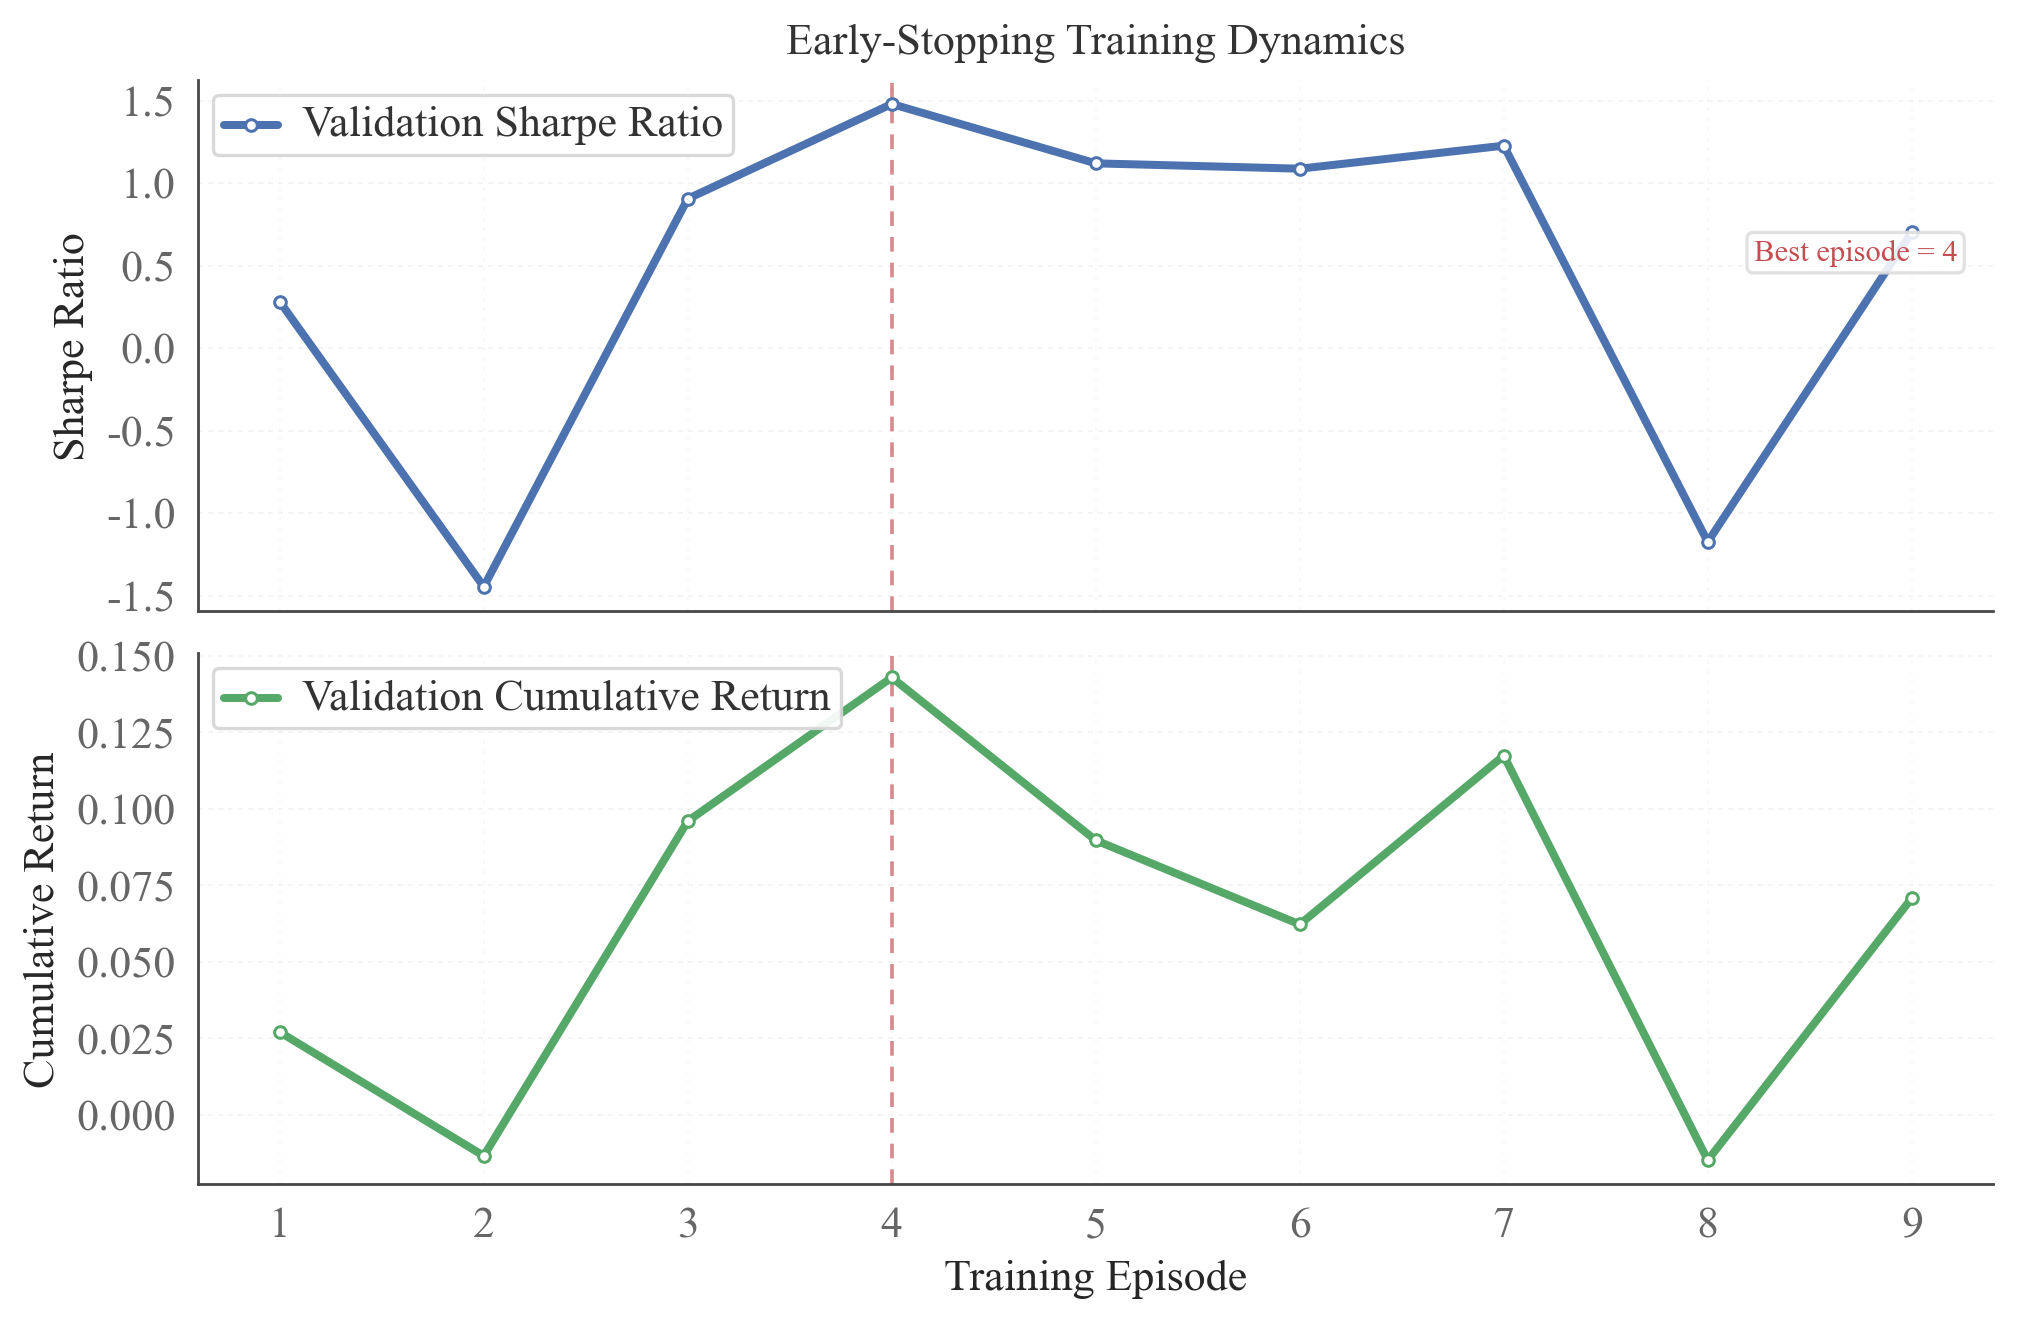

Training curves saved to: change_reward_EIIE_sse50_figures\training_curve.png


In [54]:
%config InlineBackend.figure_format = 'retina'

import os
import numpy as np
import matplotlib.pyplot as plt

%config InlineBackend.figure_format = "retina"

output_dir = "change_reward_EIIE_sse50_figures"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,

    "figure.dpi": 120,
    "savefig.dpi": 400,

    "font.size": 10.5,
    "axes.labelsize": 11.5,
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9,

    "axes.linewidth": 0.85,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.18,
    "lines.linewidth": 2.4,
})

COLOR_SHARPE = "#4C72B0"
COLOR_RETURN = "#55A868"
COLOR_BEST = "#C44E52"
GRID_COLOR = "#B8B8B8"
SPINE_COLOR = "#4A4A4A"

episodes = np.arange(1, len(history["val_sharpe"]) + 1)
best_x = best_episode

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(8.8, 5.9),
    sharex=True,
    gridspec_kw={"hspace": 0.08}
)

# Top panel: validation Sharpe ratio
ax1.plot(
    episodes,
    history["val_sharpe"],
    color=COLOR_SHARPE,
    marker="o",
    markersize=3.5,
    markerfacecolor="white",
    markeredgewidth=0.9,
    label="Validation Sharpe Ratio",
    zorder=3
)
ax1.axvline(
    best_x,
    color=COLOR_BEST,
    linestyle=(0, (4, 3)),
    linewidth=1.1,
    alpha=0.65,
    zorder=2
)
ax1.set_ylabel("Sharpe Ratio")
ax1.set_title("Early-Stopping Training Dynamics", pad=8)

ax1.grid(True, axis="y", linestyle=(0, (3, 3)), color=GRID_COLOR)
ax1.grid(True, axis="x", linestyle=(0, (2, 4)), color=GRID_COLOR, alpha=0.10)
ax1.set_axisbelow(True)

ax1.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.92,
    facecolor="white",
    edgecolor="#D6D6D6",
    borderpad=0.35,
    handlelength=1.8
)

ax1.text(
    0.98, 0.7,
    f"Best episode = {best_episode}",
    transform=ax1.transAxes,
    ha="right",
    va="top",
    fontsize=9.2,
    color=COLOR_BEST,
    bbox=dict(
        boxstyle="round,pad=0.22",
        facecolor="white",
        edgecolor="#DDDDDD",
        alpha=0.88
    )
)

# Bottom panel: validation cumulative return
ax2.plot(
    episodes,
    history["val_return"],
    color=COLOR_RETURN,
    marker="o",
    markersize=3.5,
    markerfacecolor="white",
    markeredgewidth=0.9,
    label="Validation Cumulative Return",
    zorder=3
)
ax2.axvline(
    best_x,
    color=COLOR_BEST,
    linestyle=(0, (4, 3)),
    linewidth=1.1,
    alpha=0.65,
    zorder=2
)
ax2.set_ylabel("Cumulative Return")
ax2.set_xlabel("Training Episode")

ax2.grid(True, axis="y", linestyle=(0, (3, 3)), color=GRID_COLOR)
ax2.grid(True, axis="x", linestyle=(0, (2, 4)), color=GRID_COLOR, alpha=0.10)
ax2.set_axisbelow(True)

ax2.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.92,
    facecolor="white",
    edgecolor="#D6D6D6",
    borderpad=0.35,
    handlelength=1.8
)

# Integer episode ticks
ax2.set_xticks(episodes)

# Spine and tick styling
for ax in (ax1, ax2):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(SPINE_COLOR)
    ax.spines["bottom"].set_color(SPINE_COLOR)
    ax.tick_params(
        axis="both",
        which="major",
        length=3.2,
        width=0.75,
        color=SPINE_COLOR
    )
    apply_times_new_roman(ax)

fig.subplots_adjust(
    left=0.12,
    right=0.97,
    top=0.90,
    bottom=0.12,
    hspace=0.08
)

png_path = os.path.join(output_dir, "training_curve.png")
fig.savefig(png_path, bbox_inches="tight")

plt.show()
print("Training curves saved to:", png_path)


## 6. Out-of-Sample Evaluation

The trained EIIE policy is evaluated on multiple unseen yearly periods. This allows us to examine how performance evolves as the test window moves further away from the training period.


### 6.1 Instantiate Yearly Test Environments

Three independent portfolio environments are created for 2023, 2024, and 2025. All of them use the same transaction-cost setting, feature set, and time-window length as the training environment, which keeps the out-of-sample comparison consistent.


In [55]:
environment_2023 = PortfolioOptimizationEnv(
    df_portfolio_2023,
    initial_amount=100000,
    comission_fee_pct=0,
    time_window=50,
    features=["macd","rsi_30","cci_30","dx_30","close","r1","r5","r10","r20","intraday","overnight","range",],  
    normalize_df=None
)

environment_2024 = PortfolioOptimizationEnv(
    df_portfolio_2024,
    initial_amount=100000,
    comission_fee_pct=0,
    time_window=50,
    features=["macd","rsi_30","cci_30","dx_30","close","r1","r5","r10","r20","intraday","overnight","range",],
    normalize_df=None
)

environment_2025 = PortfolioOptimizationEnv(
    df_portfolio_2025,
    initial_amount=100000,
    comission_fee_pct=0,
    time_window=50,
    features=["macd","rsi_30","cci_30","dx_30","close","r1","r5","r10","r20","intraday","overnight","range",],
    normalize_df=None
)

### 6.2 Evaluate the EIIE Policy

In this section, the notebook loads the saved best policy and runs it on each yearly test environment. For every test period, it stores three outputs:

- portfolio value trajectory;
- portfolio weight sequence (actions);
- daily turnover derived from action changes.

These stored results are later reused for the comparative figures.


In [56]:
import numpy as np

EIIE_results = {
    "training": environment._asset_memory["final"],
    "validation": {"value": list(environment_val._asset_memory["final"])},
    "2023": {},
    "2024": {},
    "2025": {}
}

# instantiate an architecture with the same arguments used in training
# and load with load_state_dict.

policy = EIIE(
    initial_features=12,
    k_size=2,
    conv_mid_features=8,
    conv_final_features=10,
    time_window=50,
    device=device,
)
policy.load_state_dict(torch.load("policy_EIIE_change_reward_best.pt"))

for year, env in [("2023", environment_2023),
                  ("2024", environment_2024),
                  ("2025", environment_2025)]:
    DRLAgent.DRL_validation(model, env, policy=policy)
    values = env._asset_memory["final"]
    actions = np.array(env._actions_memory).copy()
    turnover = np.sum(np.abs(np.diff(actions[:, 1:], axis=0)), axis=1)
    EIIE_results[year] = {
        "value":   list(values),
        "actions": np.array(env._actions_memory).copy(),
        "turnover": turnover,
    }

C:\Users\64954\AppData\Local\Temp\ipykernel_24520\3279686722.py:22: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  policy.load_state_dict(torch.load("policy_EIIE_change_rewar

Initial portfolio value:100000
Final portfolio value: 89292.46875
Final accumulative portfolio value: 0.8929246875
Maximum DrawDown: -0.1597613020776013
Sharpe ratio: -1.1656162038448117


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 100313.1328125
Final accumulative portfolio value: 1.003131328125
Maximum DrawDown: -0.00681679475930741
Sharpe ratio: 0.37336974239975906


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 102914.2890625
Final accumulative portfolio value: 1.029142890625
Maximum DrawDown: -0.013216413981870678
Sharpe ratio: 1.1948622594002931


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


### 6.3 Equal-Weight Benchmark

To provide a simple baseline, the notebook also evaluates an equal-weight strategy under the same environments. The benchmark keeps zero cash and allocates the same weight to every stock at every step.

This gives a transparent reference for judging whether the learned EIIE policy improves upon a naive diversified allocation.


In [57]:
EW_results = {
    "train": {},
    "validation": {},
    "2023": {},
    "2024": {},
    "2025": {}
}

PORTFOLIO_SIZE = len(TOP_BRL)

# train period
terminated = False
environment.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment.step(action)
EW_results["train"]["value"] = environment._asset_memory["final"]

# validation
terminated = False
environment_val.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment_val.step(action)
EW_results["validation"]["value"] = environment_val._asset_memory["final"]

# 2023
terminated = False
environment_2023.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment_2023.step(action)
EW_results["2023"]["value"] = environment_2023._asset_memory["final"]

# 2024
terminated = False
environment_2024.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment_2024.step(action)
EW_results["2024"]["value"] = environment_2024._asset_memory["final"]

# 2025
terminated = False
environment_2025.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment_2025.step(action)
EW_results["2025"]["value"] = environment_2025._asset_memory["final"]

Initial portfolio value:100000
Final portfolio value: 793264.0625
Final accumulative portfolio value: 7.932640625
Maximum DrawDown: -0.39318219686026645
Sharpe ratio: 1.2380008346249574


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 92058.5390625
Final accumulative portfolio value: 0.920585390625
Maximum DrawDown: -0.24512040871180552
Sharpe ratio: -0.3591768363036493


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 90964.0859375
Final accumulative portfolio value: 0.909640859375
Maximum DrawDown: -0.1844485088014559
Sharpe ratio: -0.7244307580930806


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 112559.96875
Final accumulative portfolio value: 1.1255996875
Maximum DrawDown: -0.12616246966049227
Sharpe ratio: 0.7694857658947477


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 110413.40625
Final accumulative portfolio value: 1.1041340625
Maximum DrawDown: -0.08914812500000002
Sharpe ratio: 1.008184295722839


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


## 7. Performance Figures

The following cells generate publication-style visualizations for the training period and the out-of-sample test periods. The figures compare EIIE with the equal-weight benchmark and summarize the model's behavior from three complementary perspectives:

- portfolio value;
- turnover;
- portfolio weights.


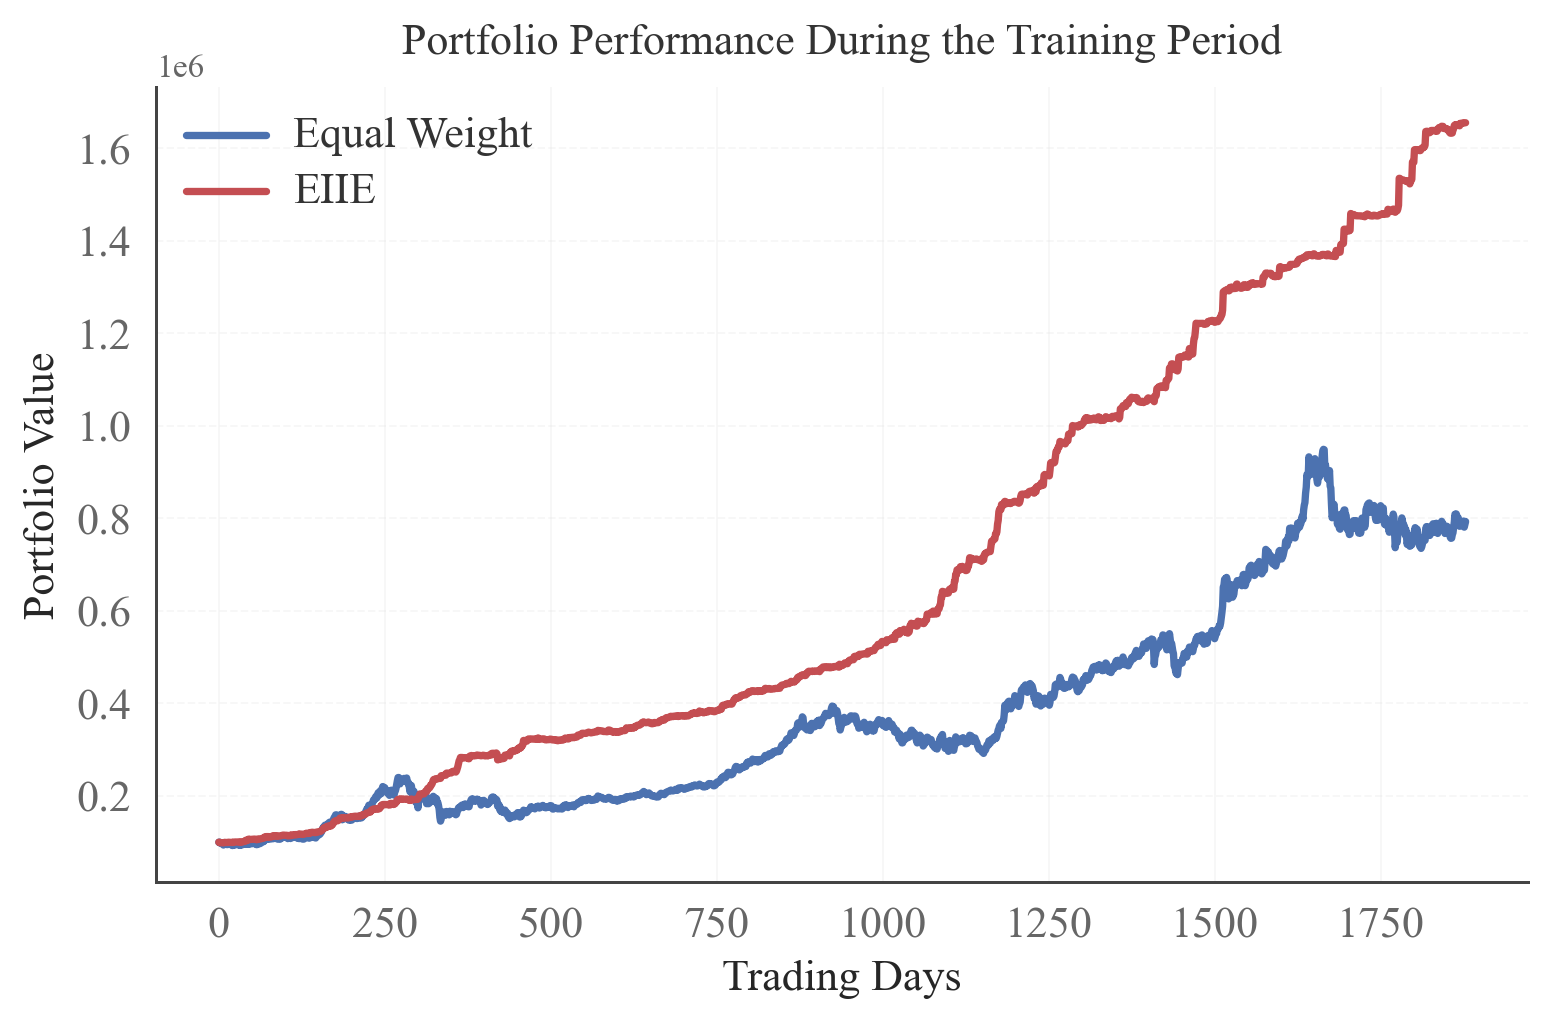

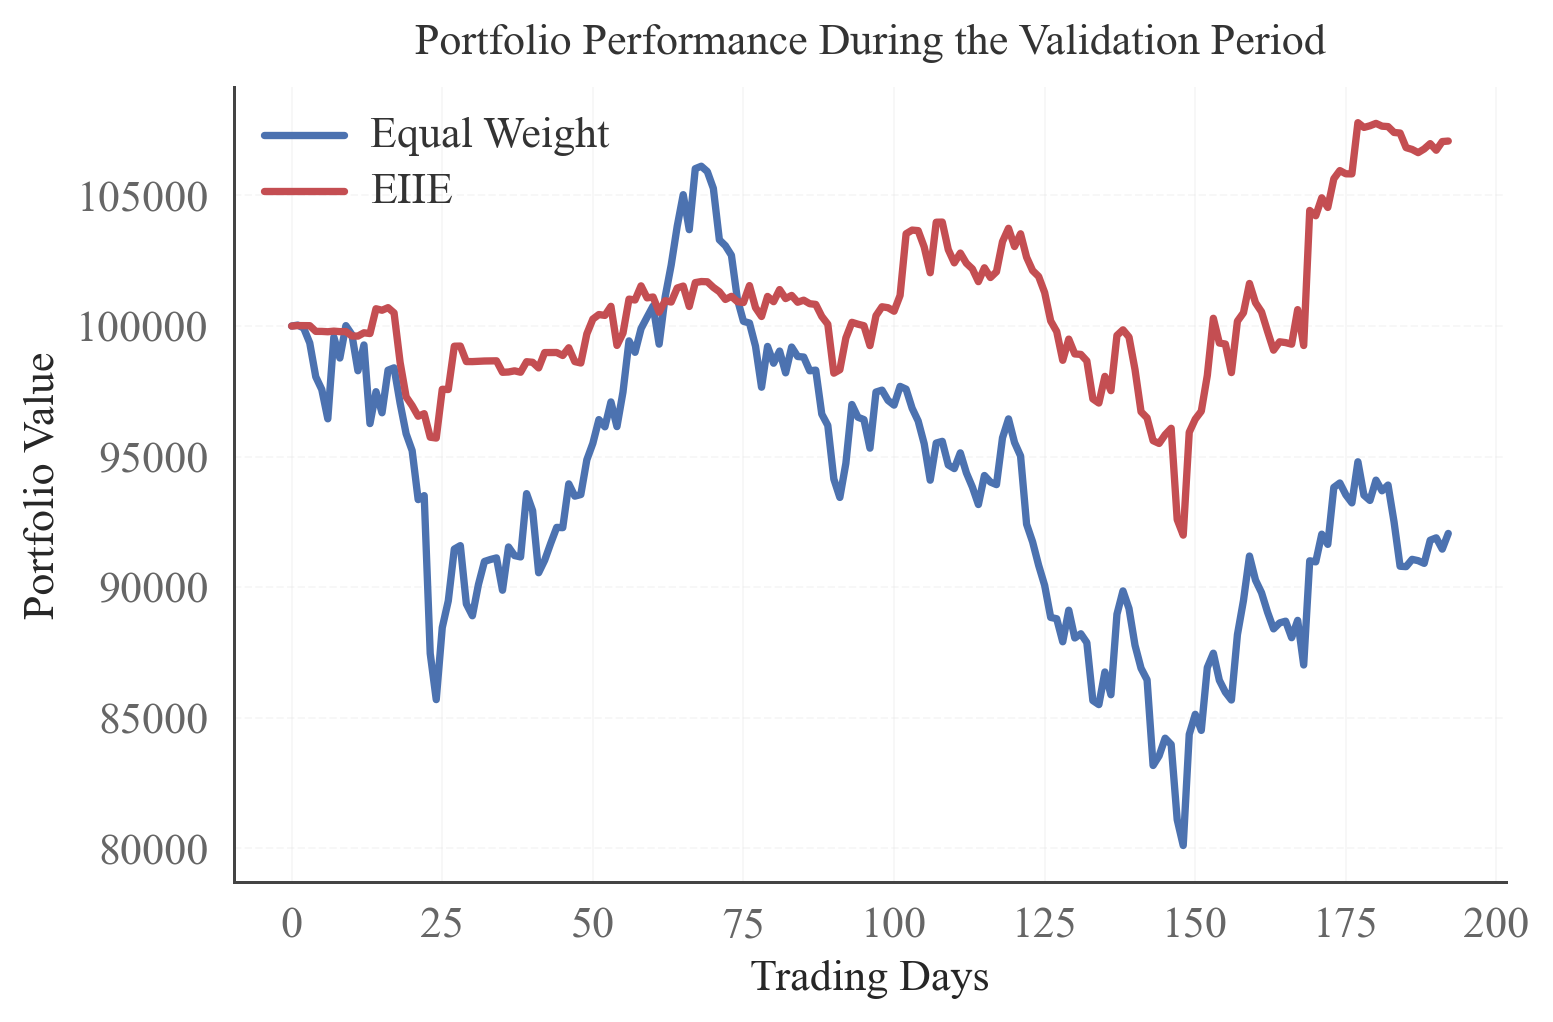

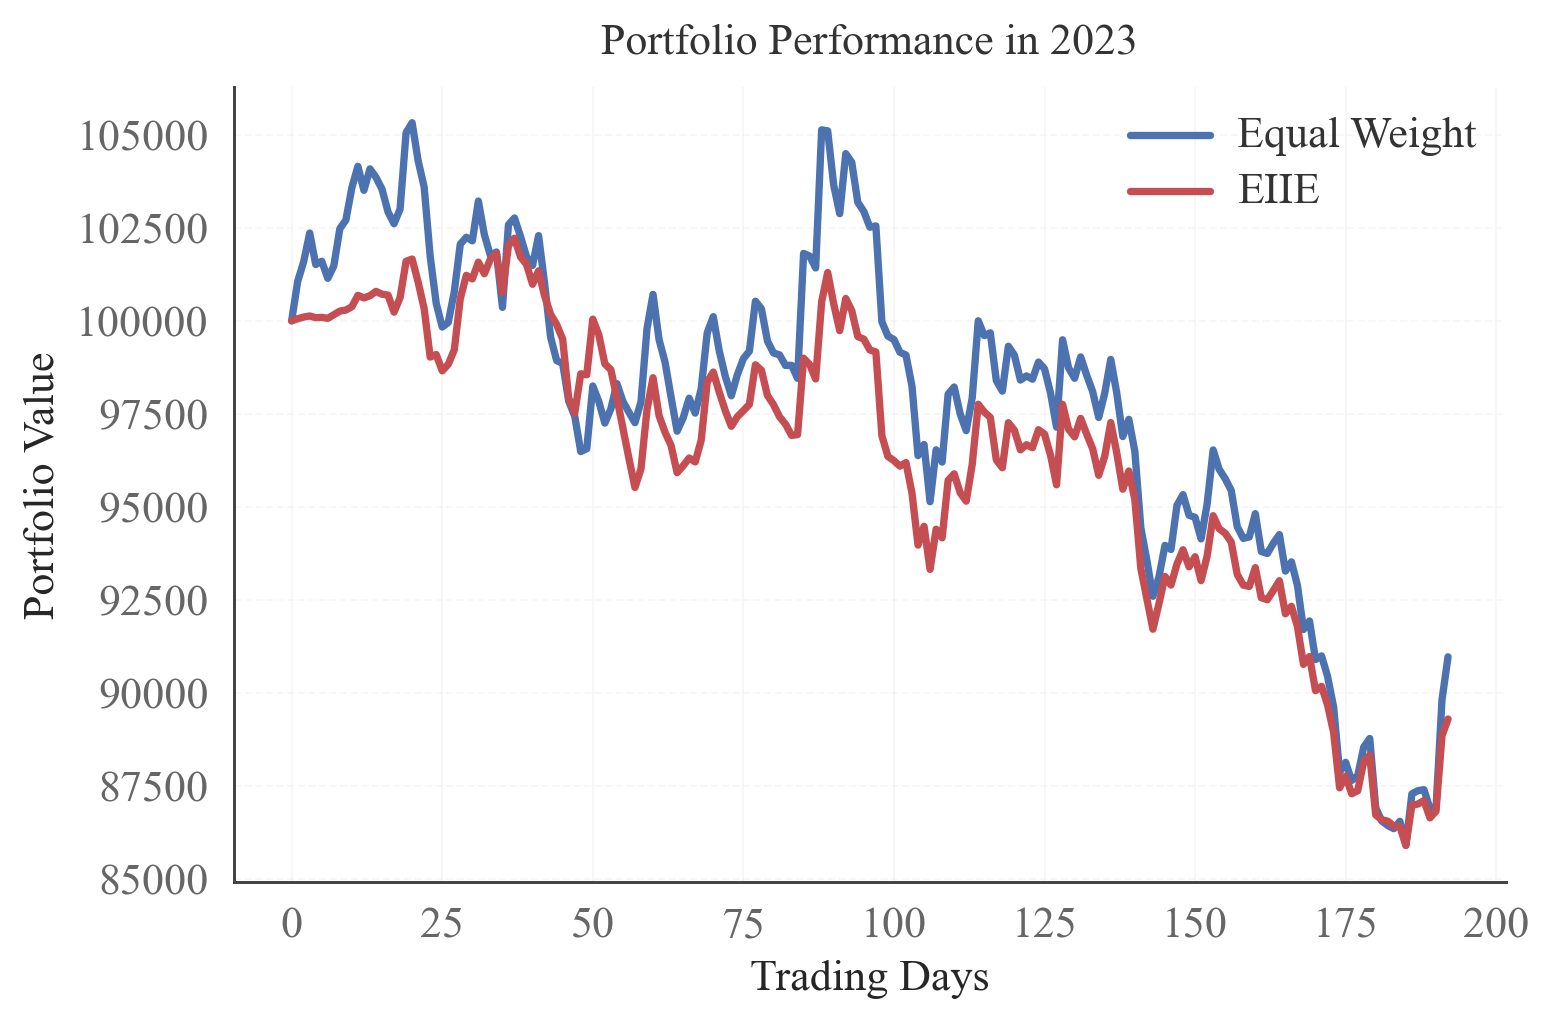

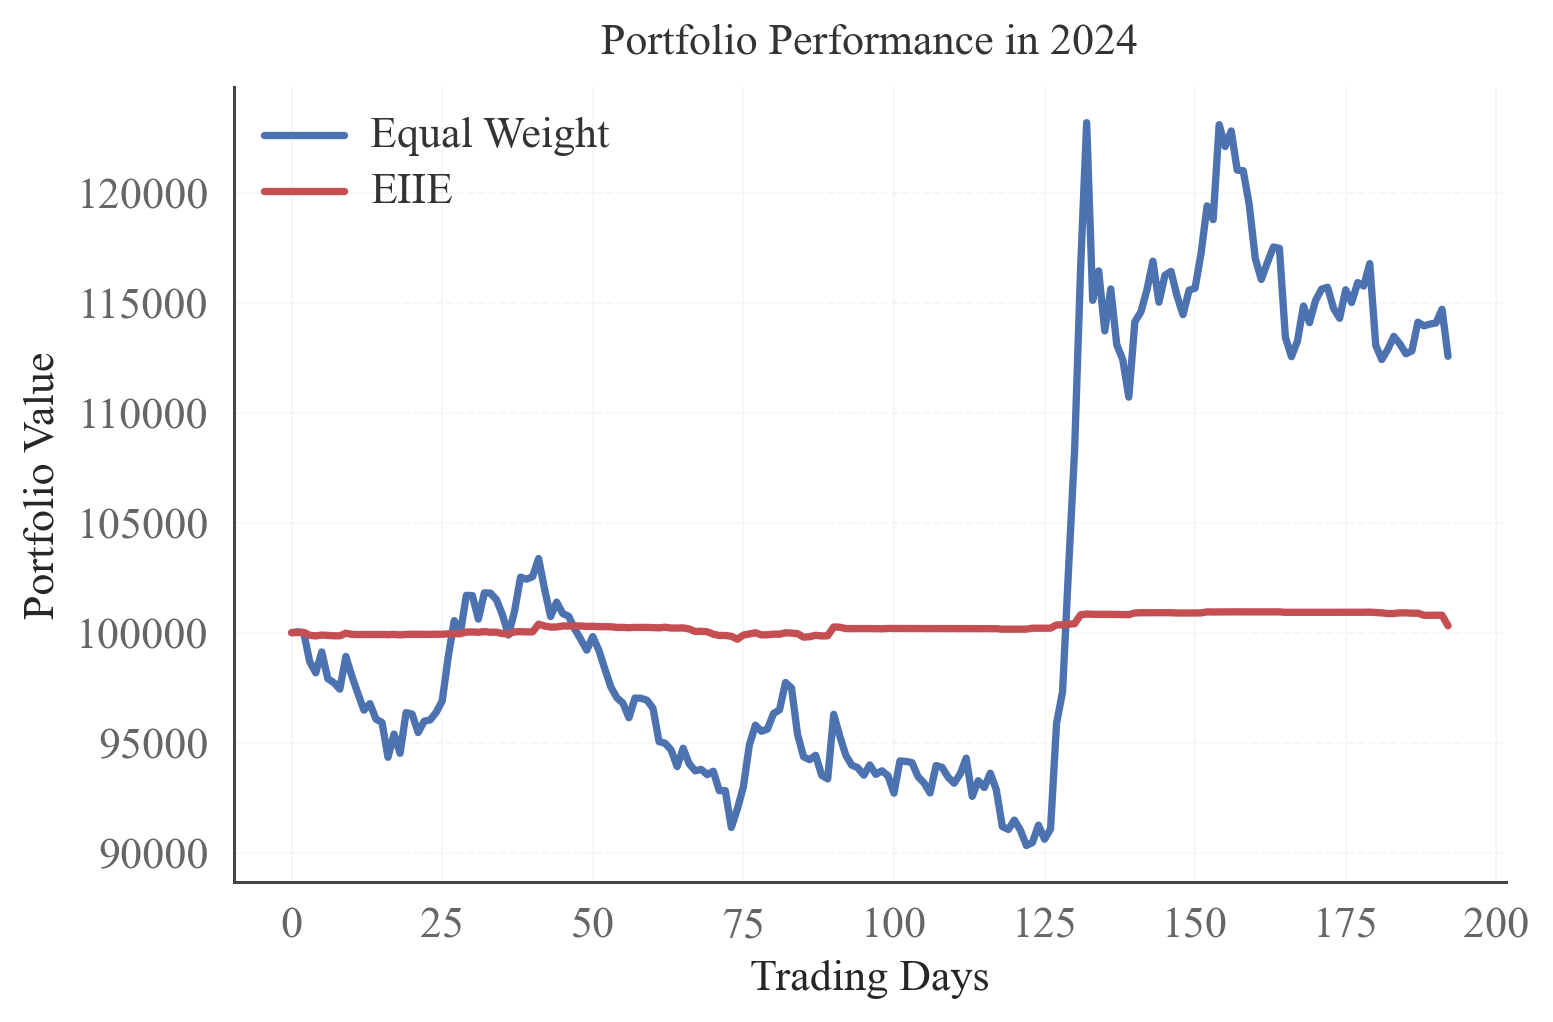

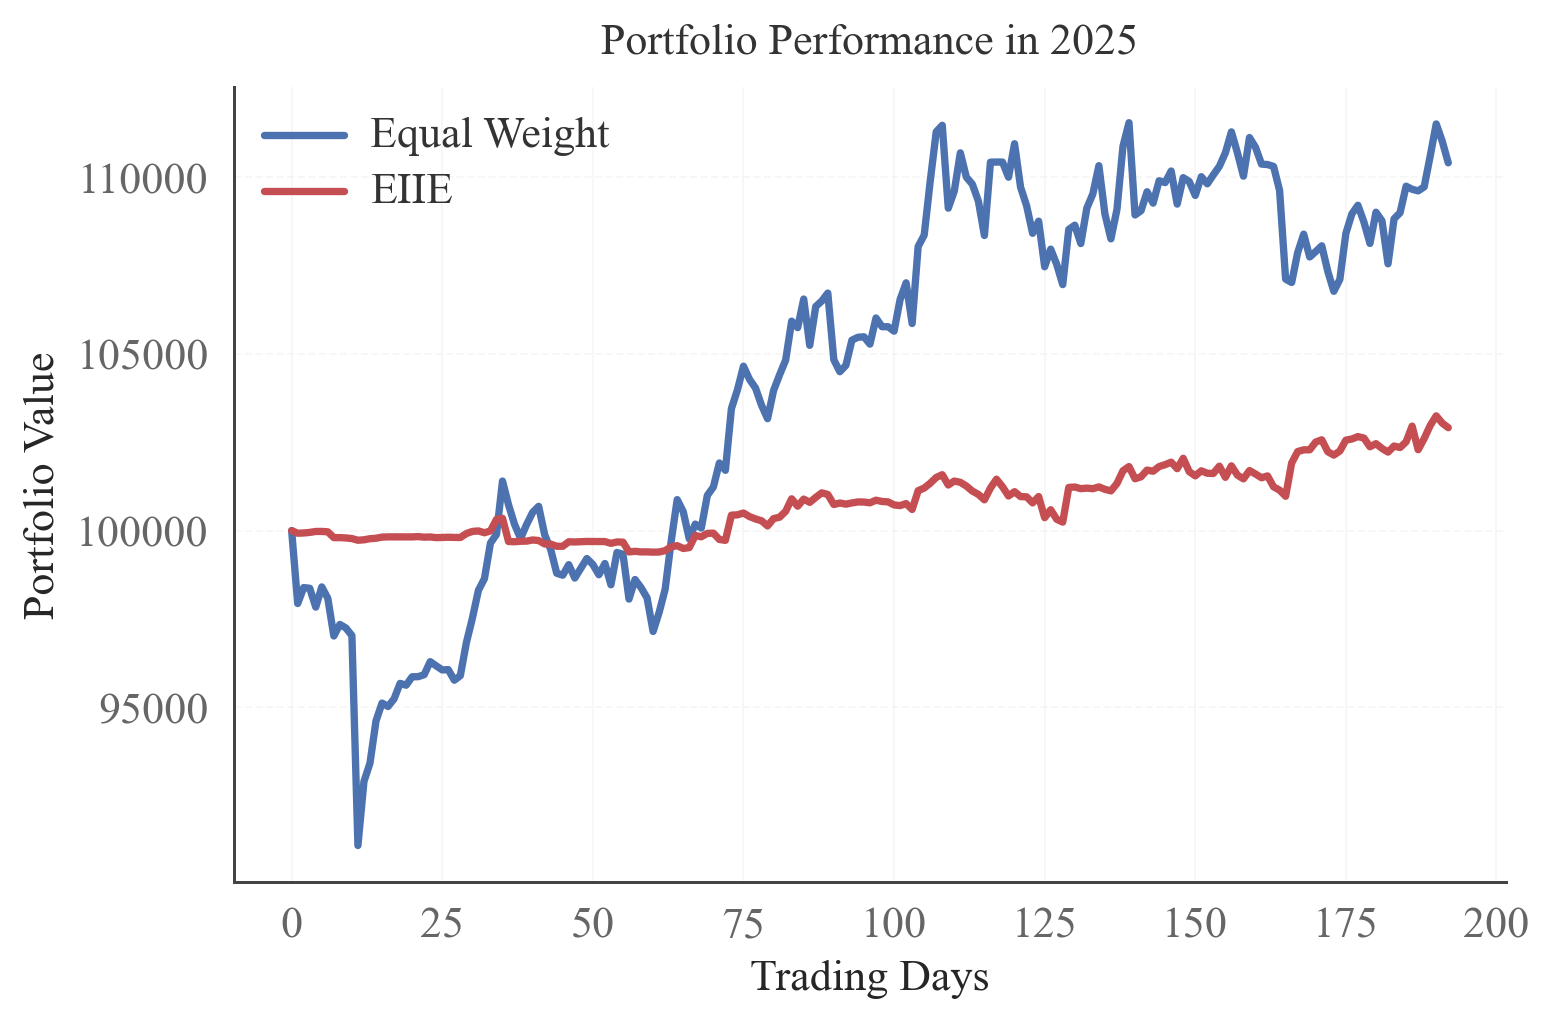

In [58]:
import os
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

output_dir = "change_reward_EIIE_sse50_figures"
os.makedirs(output_dir, exist_ok=True)

# Publication-style settings
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,

    "figure.figsize": (6.6, 4.4),
    "figure.dpi": 120,
    "savefig.dpi": 400,

    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,

    "lines.linewidth": 2.2,
    "axes.linewidth": 0.9,

    "axes.spines.top": False,
    "axes.spines.right": False,

    "legend.frameon": False,
    "legend.handlelength": 2.4,

    "grid.alpha": 0.22,
    "grid.linewidth": 0.6,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# Academic-style muted palette
COLOR_EW = "#4C72B0"
COLOR_EIIE = "#C44E52"

def plot_portfolio_value(ew_values, eiie_values, title, save_name=None):
    fig, ax = plt.subplots()

    x_ew = np.arange(len(ew_values))
    x_eiie = np.arange(len(eiie_values))

    ax.plot(
        x_ew,
        ew_values,
        label="Equal Weight",
        color=COLOR_EW,
        linewidth=2.2
    )
    ax.plot(
        x_eiie,
        eiie_values,
        label="EIIE",
        color=COLOR_EIIE,
        linewidth=2.2
    )

    ax.set_xlabel("Trading Days")
    ax.set_ylabel("Portfolio Value")
    ax.set_title(title, pad=10)

    ax.grid(True, axis="y", linestyle="--")
    ax.legend(loc="best")

    ax.spines["left"].set_color("#444444")
    ax.spines["bottom"].set_color("#444444")
    ax.tick_params(axis="both", which="major", length=4, width=0.8, color="#444444")

    apply_times_new_roman(ax)
    plt.tight_layout()

    if save_name is not None:
        fig.savefig(os.path.join(output_dir, f"{save_name}.png"), bbox_inches="tight")

    plt.show()


plot_portfolio_value(
    EW_results["train"]["value"],
    EIIE_results["training"],
    title="Portfolio Performance During the Training Period",
    save_name="value_train"
)

plot_portfolio_value(
    EW_results["validation"]["value"],
    EIIE_results["validation"]["value"],
    title="Portfolio Performance During the Validation Period",
    save_name="value_validation"
)

plot_portfolio_value(
    EW_results["2023"]["value"],
    EIIE_results["2023"]["value"],
    title="Portfolio Performance in 2023",
    save_name="value_2023"
)

plot_portfolio_value(
    EW_results["2024"]["value"],
    EIIE_results["2024"]["value"],
    title="Portfolio Performance in 2024",
    save_name="value_2024"
)

plot_portfolio_value(
    EW_results["2025"]["value"],
    EIIE_results["2025"]["value"],
    title="Portfolio Performance in 2025",
    save_name="value_2025"
)


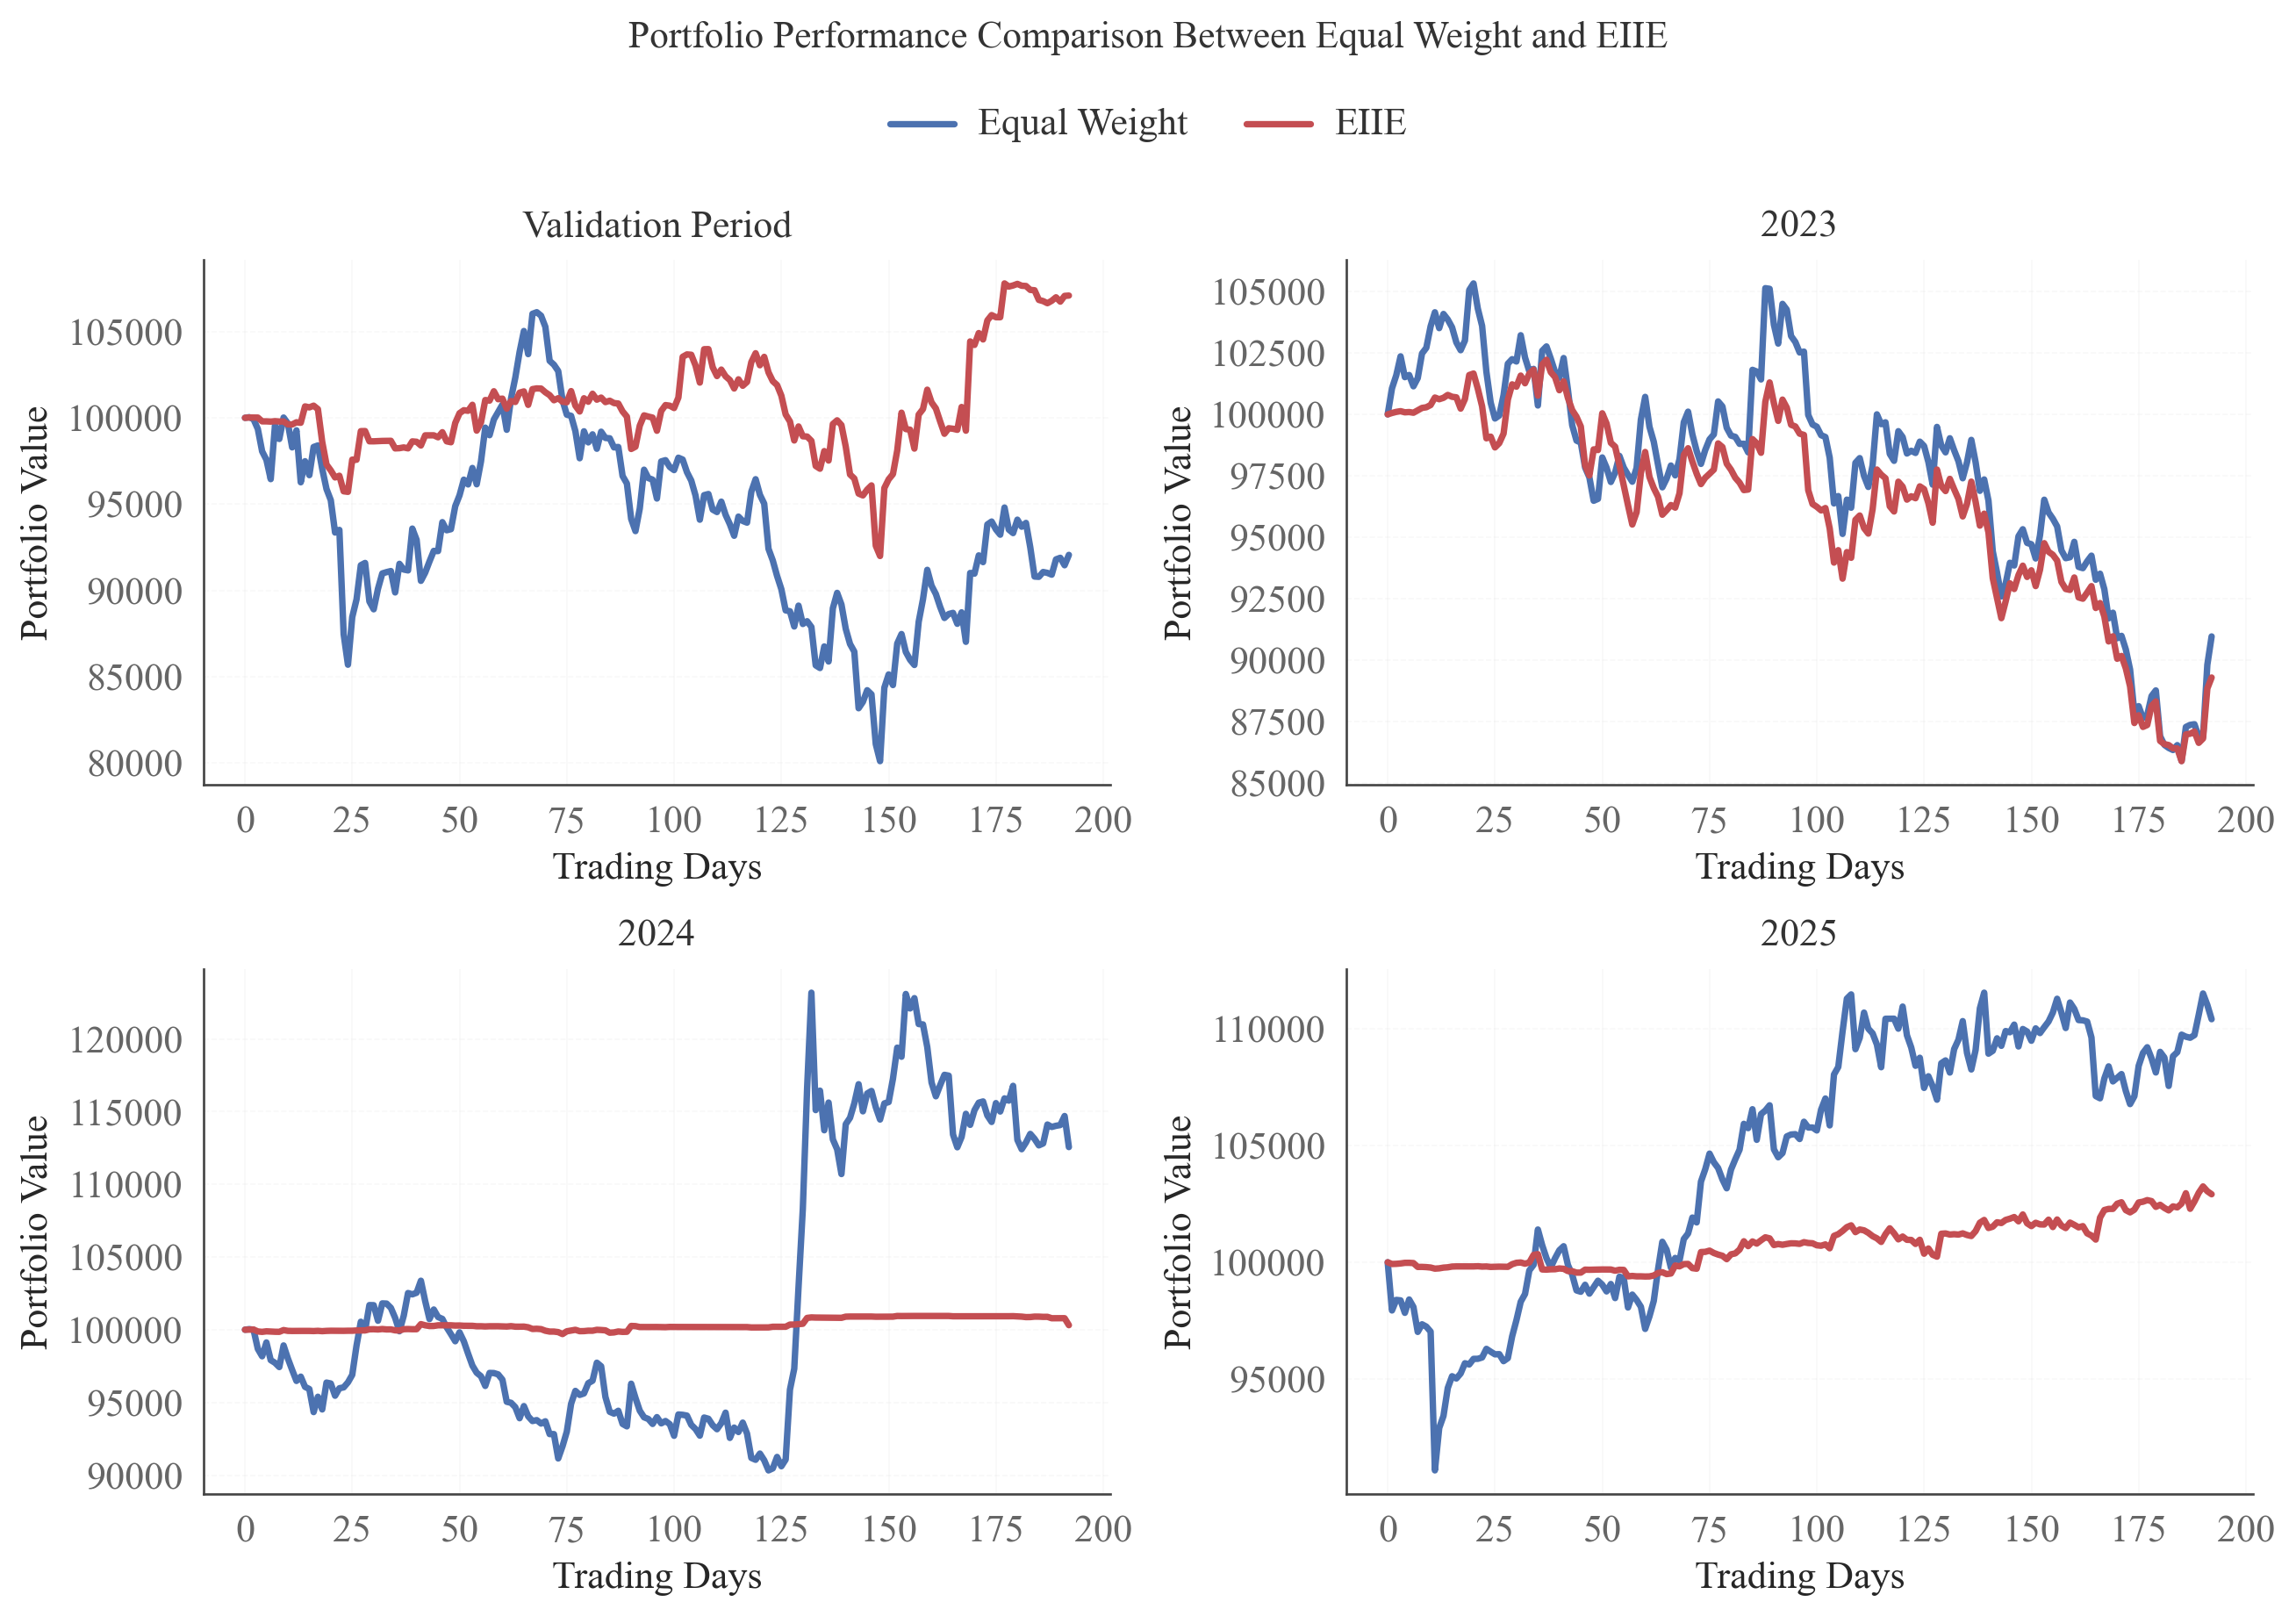

In [59]:
import os
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

output_dir = "change_reward_EIIE_sse50_figures"
os.makedirs(output_dir, exist_ok=True)

# Publication-style settings
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "axes.unicode_minus": False,

    "figure.dpi": 120,
    "savefig.dpi": 400,

    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "axes.titleweight": "semibold",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 10,

    "lines.linewidth": 2.2,
    "axes.linewidth": 0.8,

    "axes.spines.top": False,
    "axes.spines.right": False,

    "legend.frameon": False,
    "legend.handlelength": 2.2,

    "grid.alpha": 0.20,
    "grid.linewidth": 0.5,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

COLOR_EW = "#4C72B0"
COLOR_EIIE = "#C44E52"

period_data = [
    ("Validation Period", EW_results["validation"]["value"], EIIE_results["validation"]["value"]),
    ("2023", EW_results["2023"]["value"], EIIE_results["2023"]["value"]),
    ("2024", EW_results["2024"]["value"], EIIE_results["2024"]["value"]),
    ("2025", EW_results["2025"]["value"], EIIE_results["2025"]["value"]),
]

fig, axes = plt.subplots(2, 2, figsize=(11.0, 7.2))
axes = axes.flatten()

for ax, (title, ew_values, eiie_values) in zip(axes, period_data):
    x_ew = np.arange(len(ew_values))
    x_eiie = np.arange(len(eiie_values))

    ax.plot(x_ew, ew_values, color=COLOR_EW, label="Equal Weight")
    ax.plot(x_eiie, eiie_values, color=COLOR_EIIE, label="EIIE")

    ax.set_title(title, pad=8)
    ax.set_xlabel("Trading Days")
    ax.set_ylabel("Portfolio Value")

    ax.grid(True, axis="y", linestyle="--")
    ax.spines["left"].set_color("#444444")
    ax.spines["bottom"].set_color("#444444")
    ax.tick_params(axis="both", which="major", length=3.5, width=0.8, color="#444444")

# Shared legend at the top
handles, labels = axes[0].get_legend_handles_labels()
fig_legend = fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.02),
    frameon=False
)
apply_times_new_roman_to_legend(fig_legend)

fig.suptitle("Portfolio Performance Comparison Between Equal Weight and EIIE", fontsize=13, y=1.06, fontproperties=TNR_FONT)
for ax in axes:
    apply_times_new_roman(ax)
fig.tight_layout()

fig.savefig(os.path.join(output_dir, "portfolio_performance_comparison.png"), bbox_inches="tight")

plt.show()


### 7.1 Turnover Comparison

Turnover is computed from the day-to-day change in the non-cash asset weights. The multi-panel figure below reports the turnover sequence for 2023, 2024, and 2025, together with the average turnover in each year.

This helps assess how aggressively the learned strategy trades and whether trading activity changes across different market regimes.


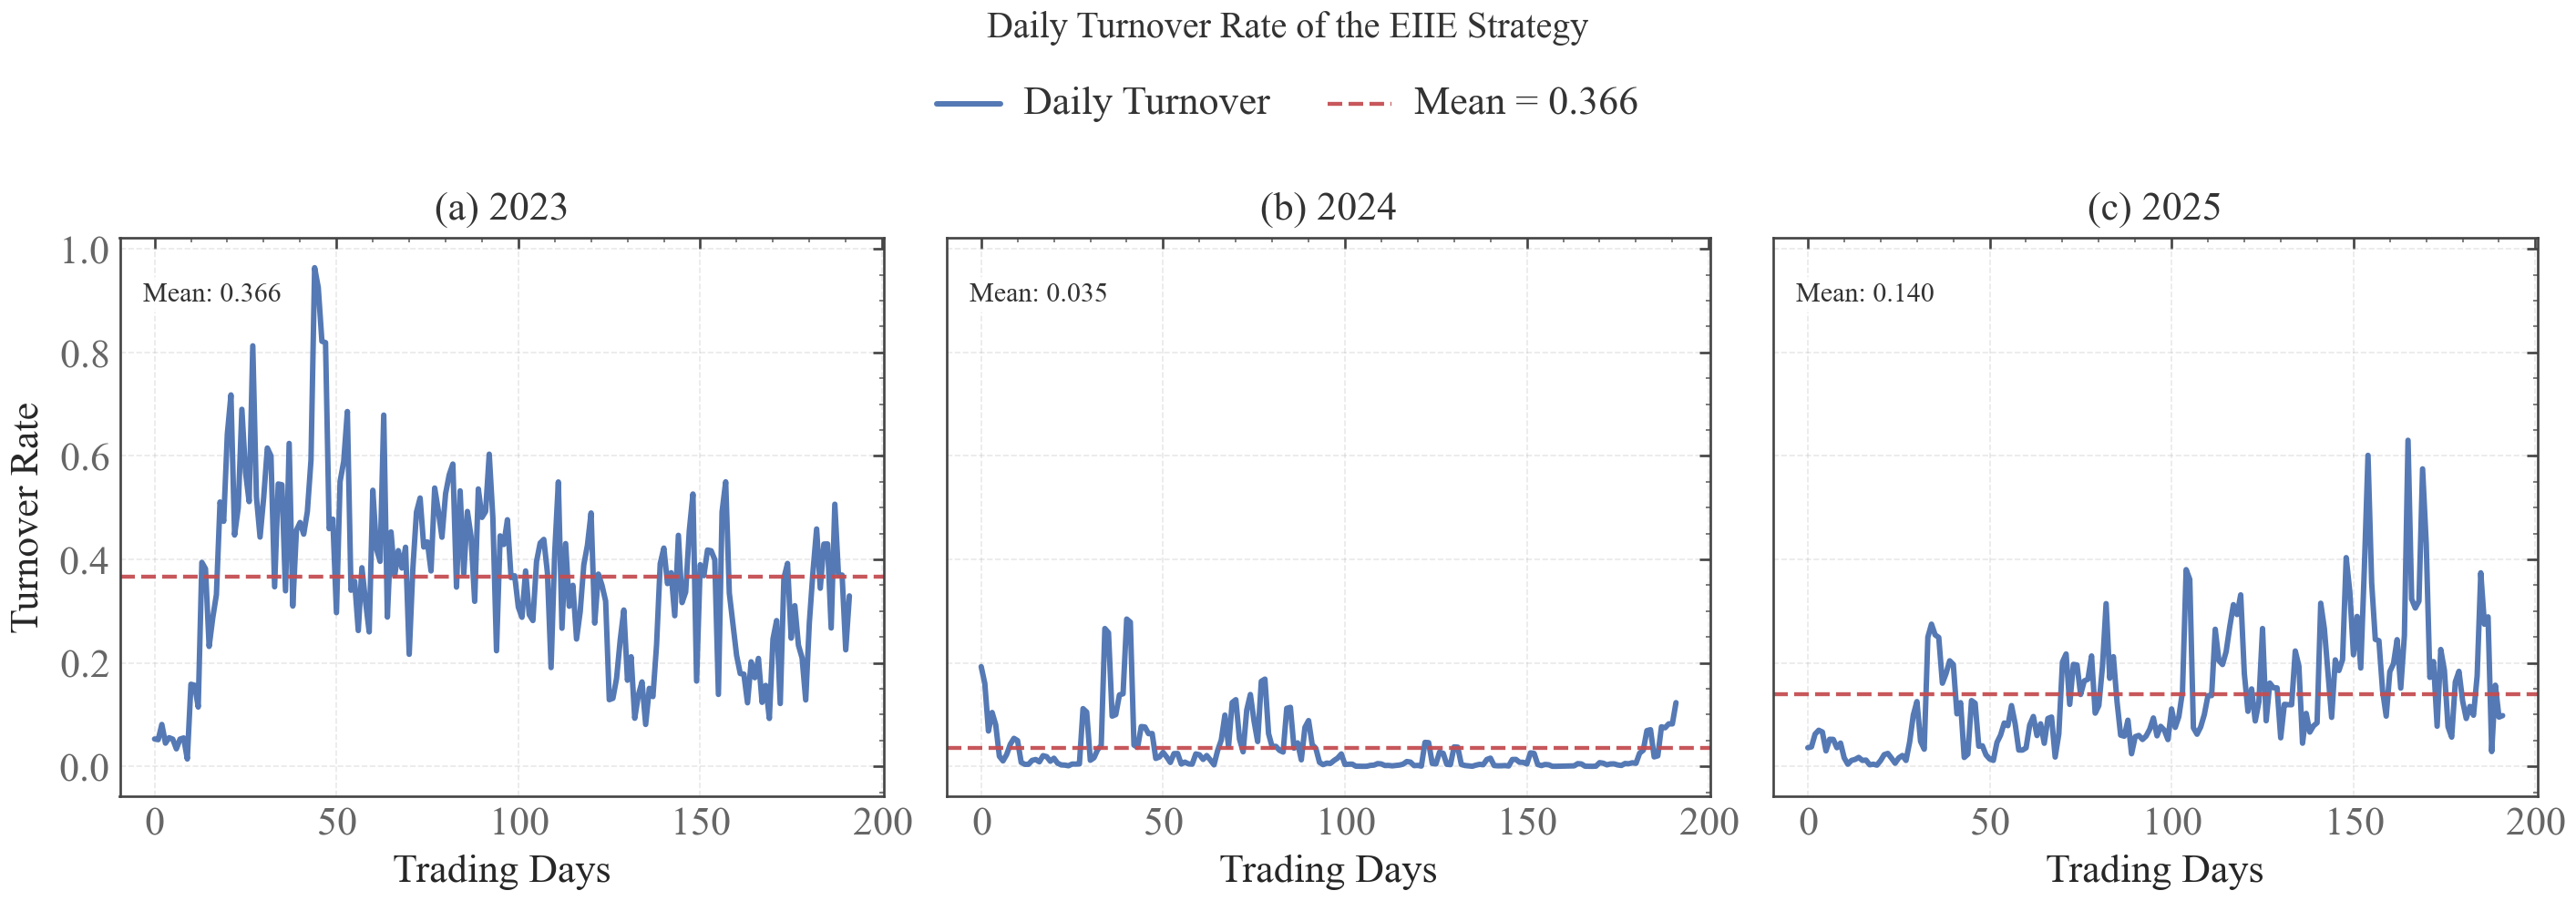

In [60]:
%config InlineBackend.figure_format = "retina"

import os
import numpy as np
import matplotlib.pyplot as plt
import scienceplots

output_dir = "change_reward_EIIE_sse50_figures"
os.makedirs(output_dir, exist_ok=True)

with plt.style.context(["science", "no-latex"]):
    plt.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
        "axes.unicode_minus": False,

        "axes.titlesize": 11,
        "axes.labelsize": 11,
        "xtick.labelsize": 9.5,
        "ytick.labelsize": 9.5,
        "legend.fontsize": 9.5,

        "axes.linewidth": 0.9,
        "grid.linewidth": 0.5,
        "grid.alpha": 0.28,
        "lines.linewidth": 1.8,

        "savefig.dpi": 400,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    years = ["2023", "2024", "2025"]
    panel_labels = ["(a)", "(b)", "(c)"]

    fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.8), sharey=True)

    line_color = "#4C72B0"
    mean_color = "#C44E52"

    all_turnover = []
    for year in years:
        all_turnover.extend(EIIE_results[year]["turnover"])

    y_min = min(all_turnover)
    y_max = max(all_turnover)
    y_margin = 0.06 * (y_max - y_min) if y_max > y_min else 0.02

    for ax, year, panel in zip(axes, years, panel_labels):
        turnover = np.asarray(EIIE_results[year]["turnover"])
        days = np.arange(len(turnover))
        mean_turnover = turnover.mean()

        ax.plot(
            days,
            turnover,
            color=line_color,
            linewidth=1.8,
            alpha=0.95,
            label="Daily Turnover"
        )

        ax.axhline(
            mean_turnover,
            linestyle="--",
            linewidth=1.3,
            color=mean_color,
            alpha=0.95,
            label=f"Mean = {mean_turnover:.3f}"
        )

        ax.set_title(f"{panel} {year}", pad=6)
        ax.set_xlabel("Trading Days")
        ax.set_ylim(y_min - y_margin, y_max + y_margin)

        if ax is axes[0]:
            ax.set_ylabel("Turnover Rate")

        ax.grid(True, linestyle="--", color="#B0B0B0")
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(0.8)
            spine.set_color("#444444")

        ax.tick_params(axis="both", which="major", length=3.5, width=0.8, color="#444444")

        ax.text(
            0.03, 0.92,
            f"Mean: {mean_turnover:.3f}",
            transform=ax.transAxes,
            fontsize=9,
            ha="left",
            va="top",
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor="none",
                alpha=0.85
            )
        )

    handles, labels = axes[0].get_legend_handles_labels()
    fig_legend = fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.04),
        ncol=2,
        frameon=False
    )
    apply_times_new_roman_to_legend(fig_legend)

    fig.suptitle("Daily Turnover Rate of the EIIE Strategy", fontsize=12, y=1.10, fontproperties=TNR_FONT)
    for ax in axes:
        apply_times_new_roman(ax)
    fig.tight_layout()

    fig.savefig(os.path.join(output_dir, "turnover_comparison.png"), bbox_inches="tight")

    plt.show()


The portfolio-value and turnover plots should be read jointly. The value curves describe the investment outcome, while the turnover figure provides a trading-intensity explanation for that outcome.

If performance deteriorates as the test period moves further away from the training window, that is a sign of temporal distribution shift rather than a plotting artifact. In that case, retraining with a more recent rolling window or expanding the feature set would be a natural next step.


### 7.2 Portfolio Weight Visualization

The final section visualizes the EIIE allocation weights. The notebook first keeps a simple single-year plotting version for inspection, and then uses a three-panel publication-style figure to summarize the dominant allocations in 2023, 2024, and 2025.

Non-dominant assets are faded into the background, while the largest average allocations remain highlighted. This makes the concentration pattern of the strategy much easier to interpret.


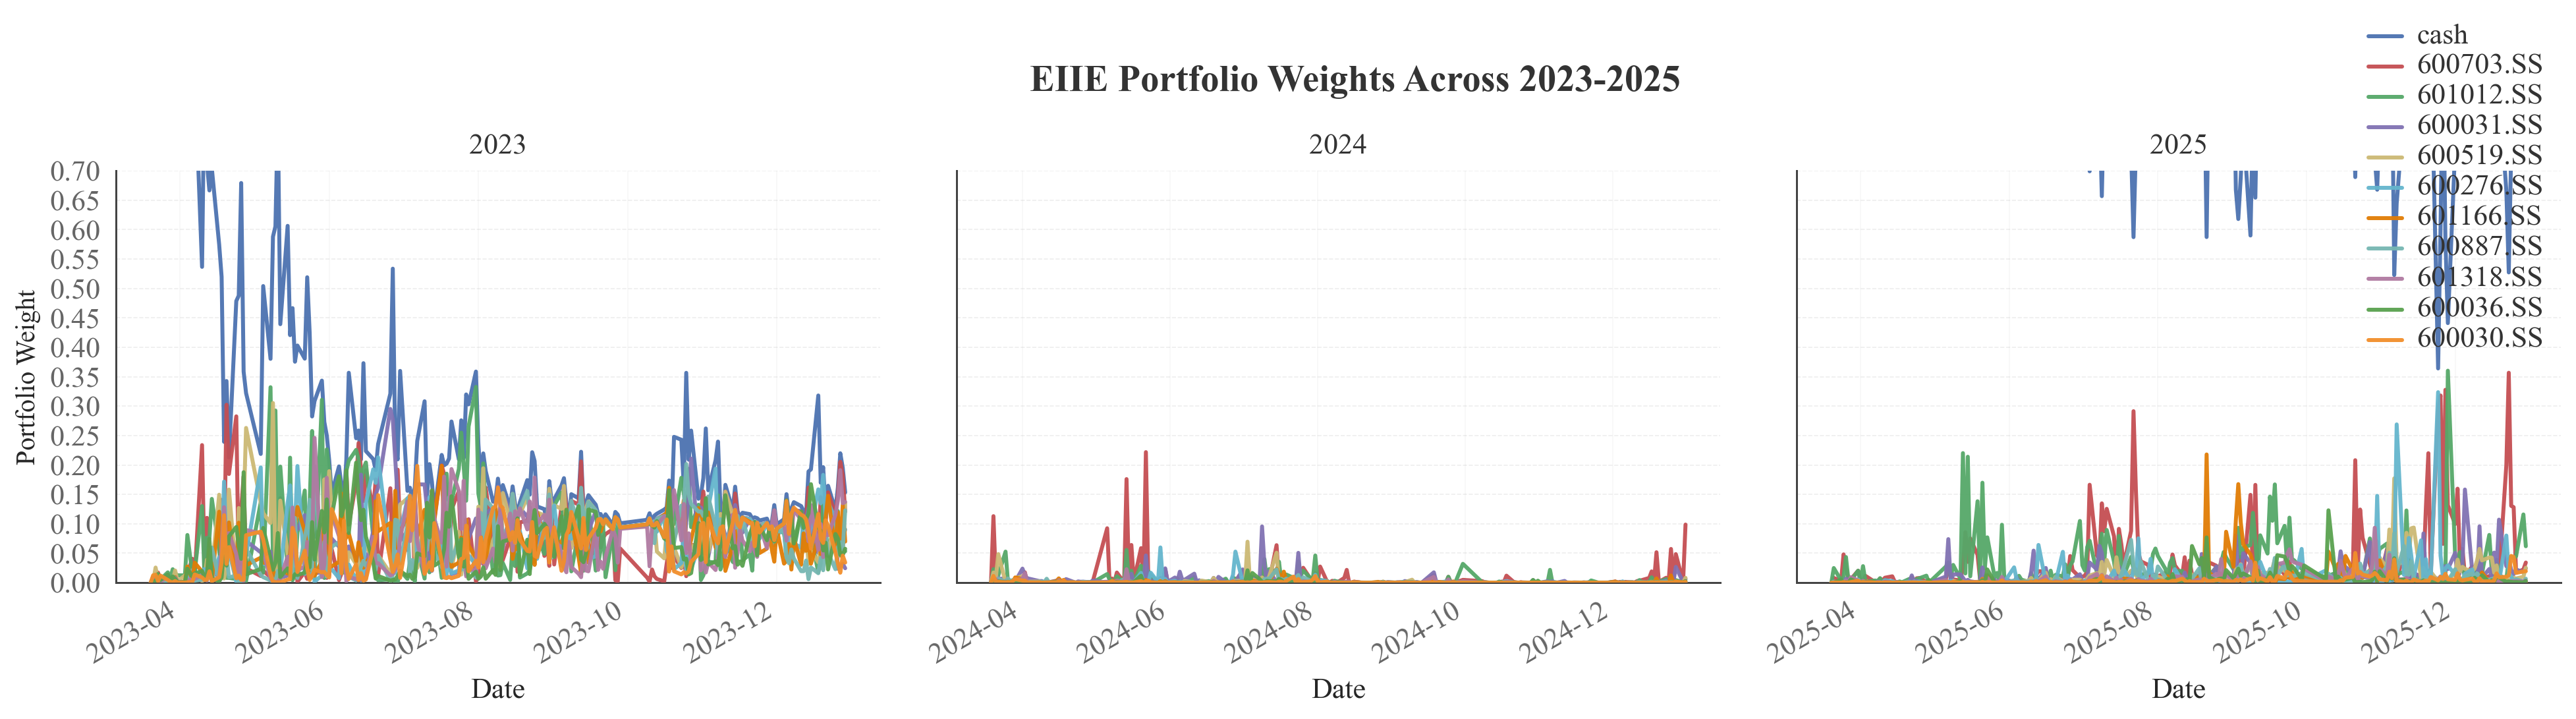

In [61]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

%config InlineBackend.figure_format = "retina"

output_dir = "change_reward_EIIE_sse50_figures"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "axes.unicode_minus": False,

    "figure.dpi": 120,
    "savefig.dpi": 400,

    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 14,
    "axes.titleweight": "semibold",
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 8.5,

    "axes.linewidth": 0.9,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.22,
    "lines.linewidth": 1.8,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

HIGHLIGHT_COLORS = [
    "#4C72B0", "#C44E52", "#55A868", "#8172B2", "#CCB974",
    "#64B5CD", "#E17C05", "#76B7B2", "#B07AA1", "#59A14F",
    "#F28E2B", "#8C8C8C"
]

def _prepare_action_plot_data(actions, raw_df, top_k=11, highlight_cash=True):
    actions = np.asarray(actions, dtype=np.float32)

    dates = sorted(pd.to_datetime(raw_df["date"]).unique())
    n_steps = actions.shape[0]
    x_dates = pd.to_datetime(dates[-n_steps:]) if len(dates) >= n_steps else np.arange(n_steps)

    tics = sorted(raw_df["tic"].unique().tolist())
    if actions.shape[1] == len(tics) + 1:
        labels = ["cash"] + tics
    else:
        labels = [f"asset_{i}" for i in range(actions.shape[1])]

    avg_weights = actions.mean(axis=0)
    sorted_idx = np.argsort(avg_weights)[::-1]

    if highlight_cash and labels[0] == "cash":
        cash_idx = 0
        stock_idx = [i for i in sorted_idx if i != cash_idx]
        highlight_idx = [cash_idx] + stock_idx[:top_k]
    else:
        highlight_idx = sorted_idx[:top_k]

    return actions, x_dates, labels, highlight_idx

def plot_actions_triptych(
    result_dict,
    raw_df_dict,
    years=("2023", "2024", "2025"),
    save_path=None,
    top_k=11,
    y_max=0.7,
):
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.2), sharey=True)

    for ax, year in zip(axes, years):
        actions, x_dates, labels, highlight_idx = _prepare_action_plot_data(
            result_dict[year]["actions"],
            raw_df_dict[year],
            top_k=top_k,
            highlight_cash=True
        )

        # background assets
        for i in range(actions.shape[1]):
            if i in highlight_idx:
                continue
            ax.plot(
                x_dates,
                actions[:, i],
                color="#C8C8C8",
                linewidth=0.7,
                alpha=0.16,
                zorder=1
            )

        # highlighted assets
        for j, i in enumerate(highlight_idx):
            ax.plot(
                x_dates,
                actions[:, i],
                color=HIGHLIGHT_COLORS[j % len(HIGHLIGHT_COLORS)],
                linewidth=1.8,
                alpha=0.95,
                label=labels[i],
                zorder=3
            )

        ax.set_title(year, pad=8, fontsize=15)
        ax.set_xlabel("Date")
        ax.set_ylim(0.0, y_max)

        ax.grid(True, axis="y", linestyle="--", color="#B0B0B0")
        ax.set_axisbelow(True)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_color("#444444")
        ax.spines["bottom"].set_color("#444444")
        ax.tick_params(axis="both", which="major", length=3.5, width=0.8, color="#444444")

        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

        ax.set_yticks(np.arange(0.0, y_max + 1e-9, 0.05))

        if ax is axes[-1]:
            ax.legend(
                loc="upper right",
                bbox_to_anchor=(1.00, 1.4),
                ncol=1,
                frameon=False,
                labelspacing=0.25,
                handlelength=1.8
            )
        apply_times_new_roman(ax)

    axes[0].set_ylabel("Portfolio Weight", fontsize=12)

    fig.suptitle(
        "EIIE Portfolio Weights Across 2023-2025",
        fontsize=17,
        x=0.53,
        y=0.98,
        fontweight="semibold",
        fontproperties=TNR_FONT
    )

    # Compress whitespace
    fig.subplots_adjust(
        left=0.055,
        right=0.992,
        bottom=0.20,
        top=0.82,
        wspace=0.10
    )

    fig.savefig(save_path, bbox_inches="tight")

    plt.show()


plot_actions_triptych(
    result_dict=EIIE_results,
    raw_df_dict={
        "2023": df_portfolio_2023,
        "2024": df_portfolio_2024,
        "2025": df_portfolio_2025,
    },
    years=("2023", "2024", "2025"),
    save_path=os.path.join(output_dir, "EIIE_weights_triptych.png"),
    top_k=11,
    y_max=0.7
)


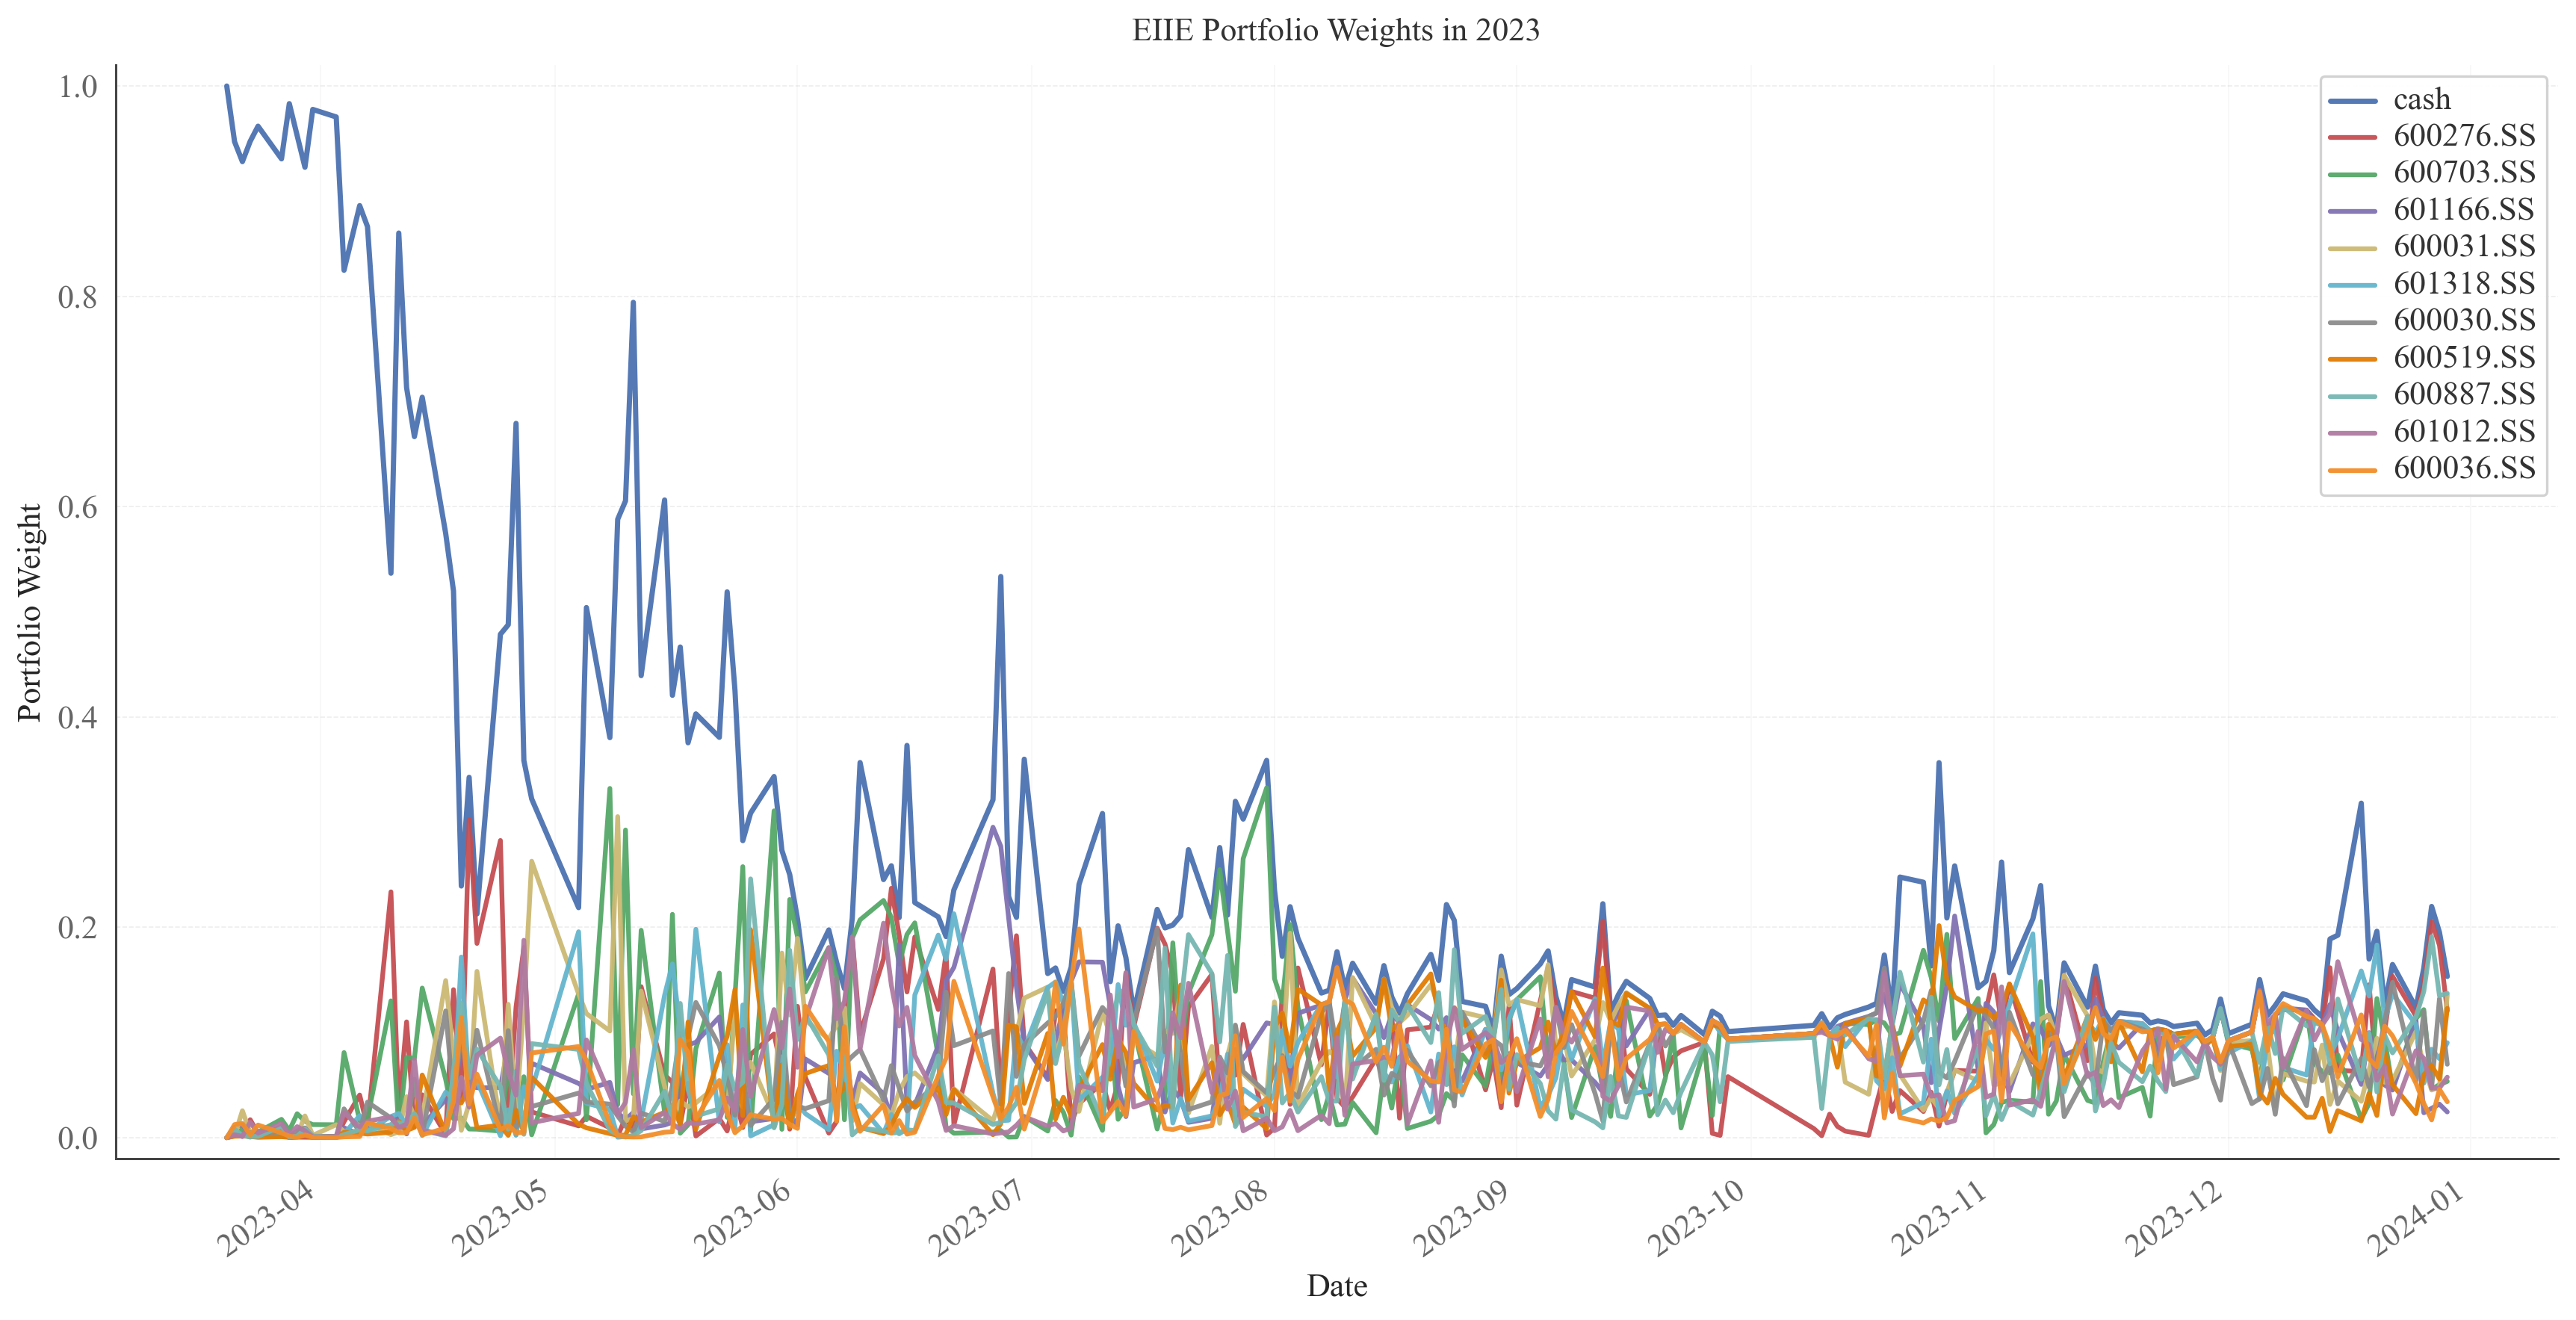

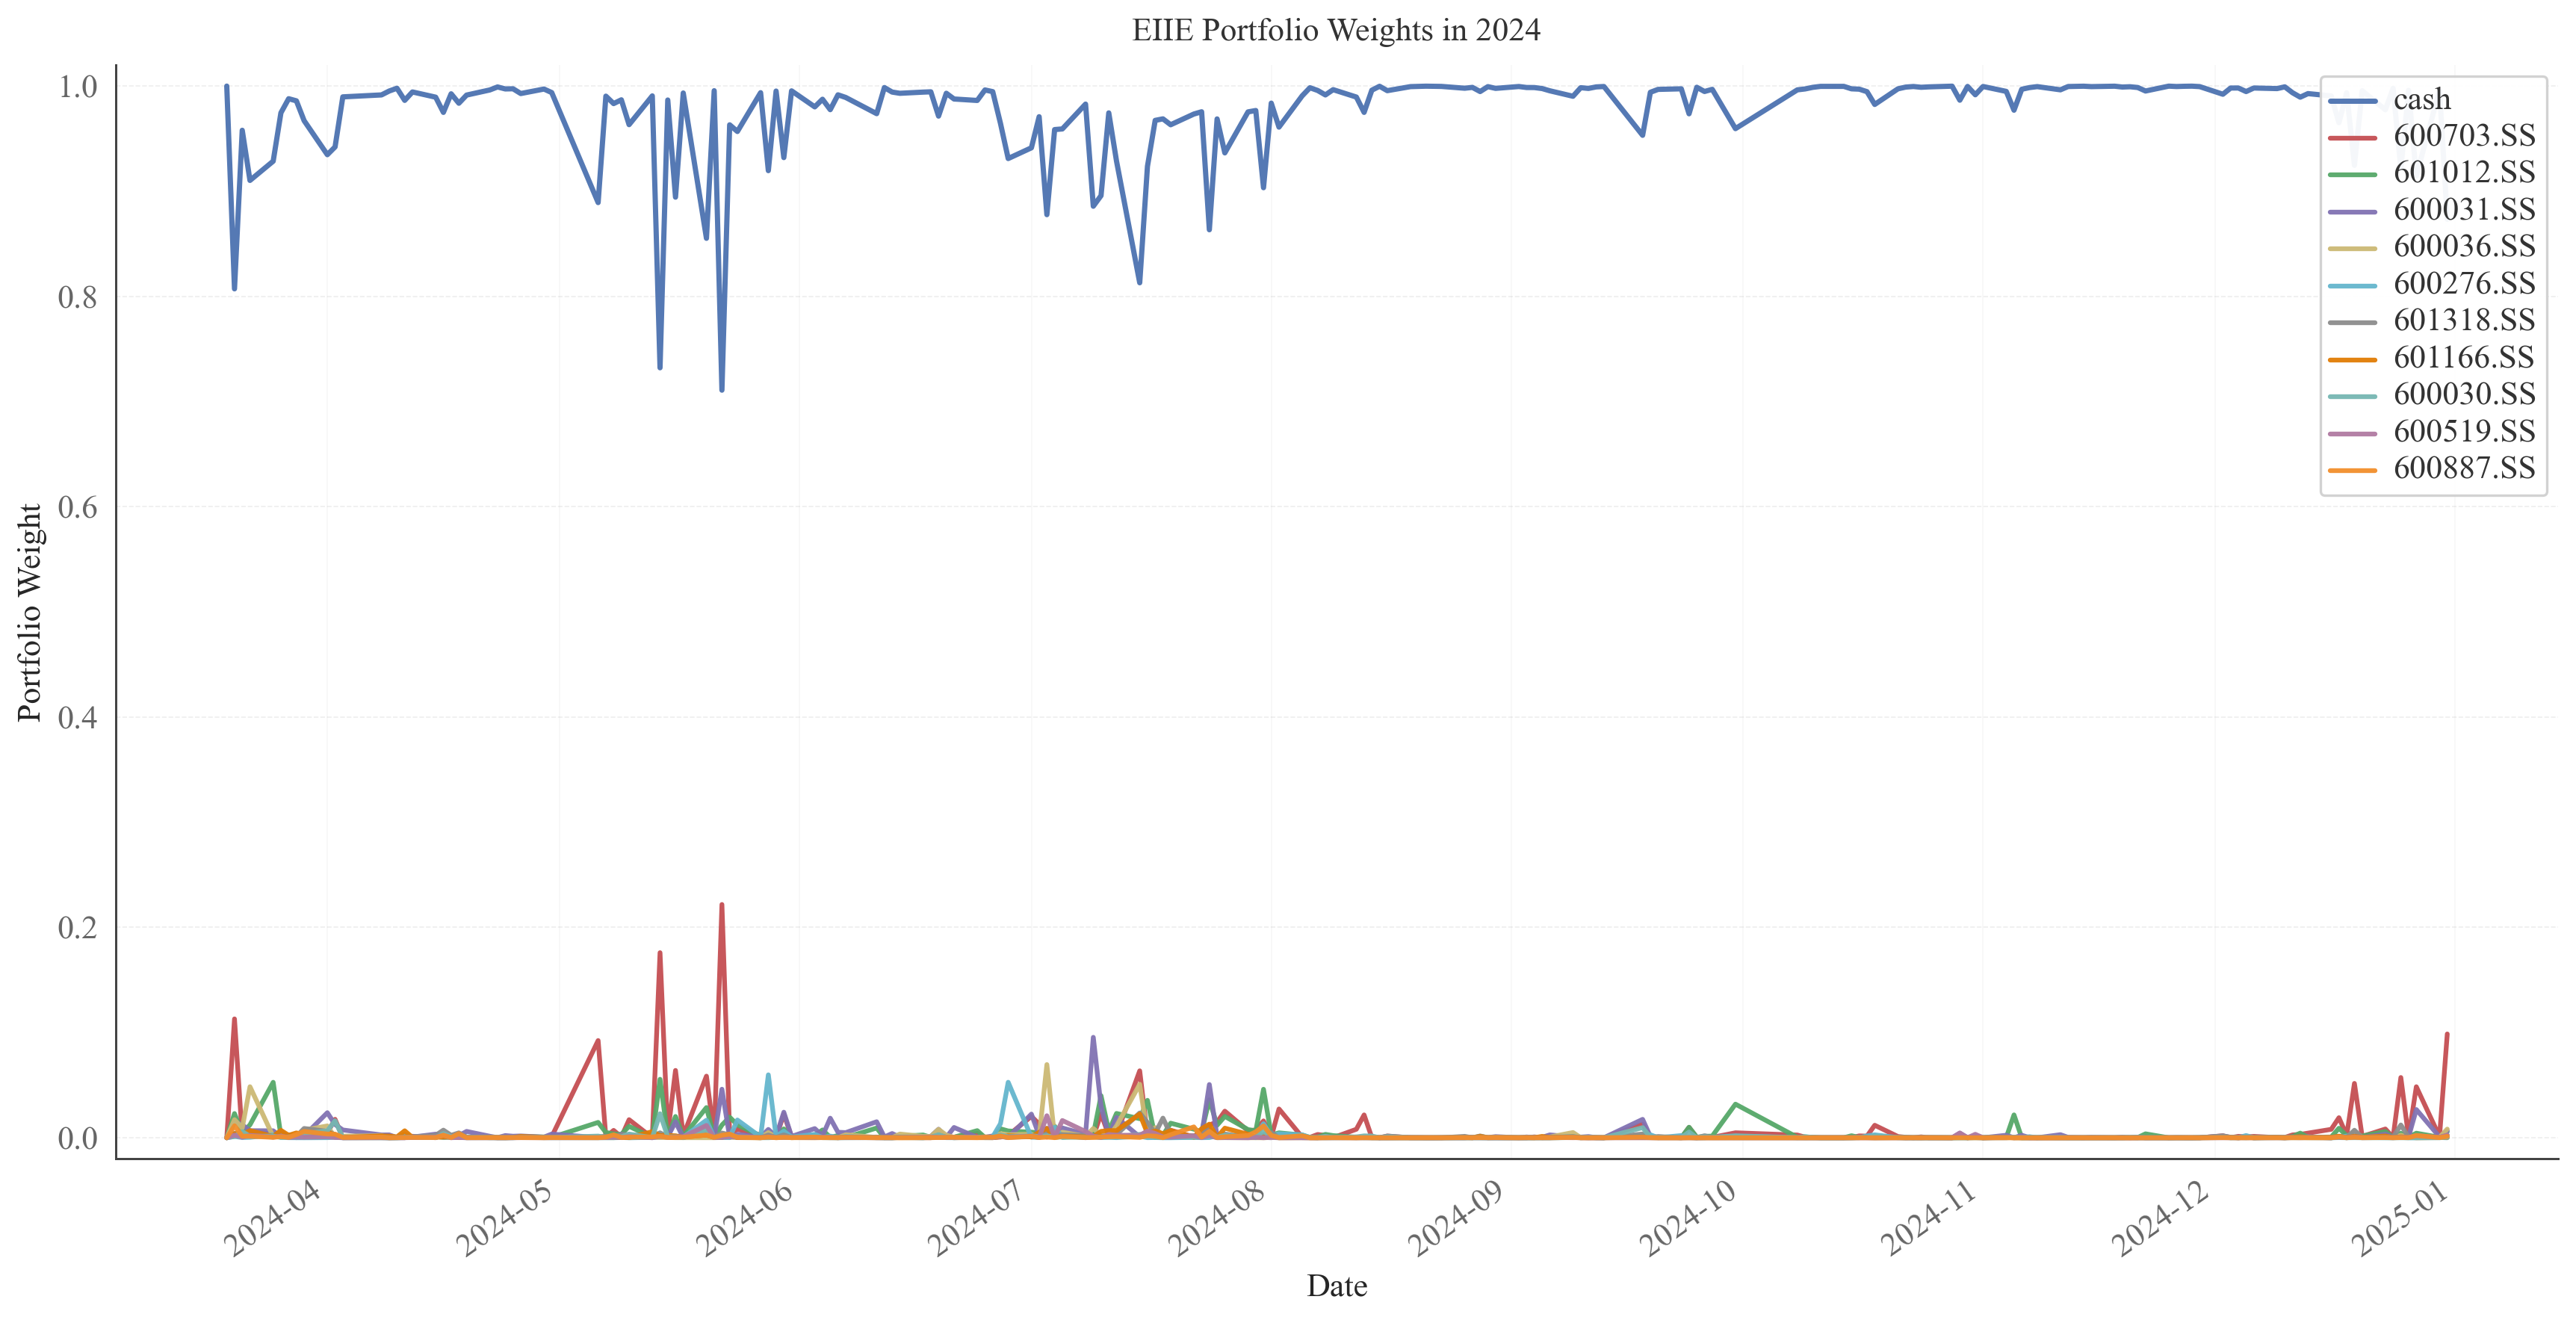

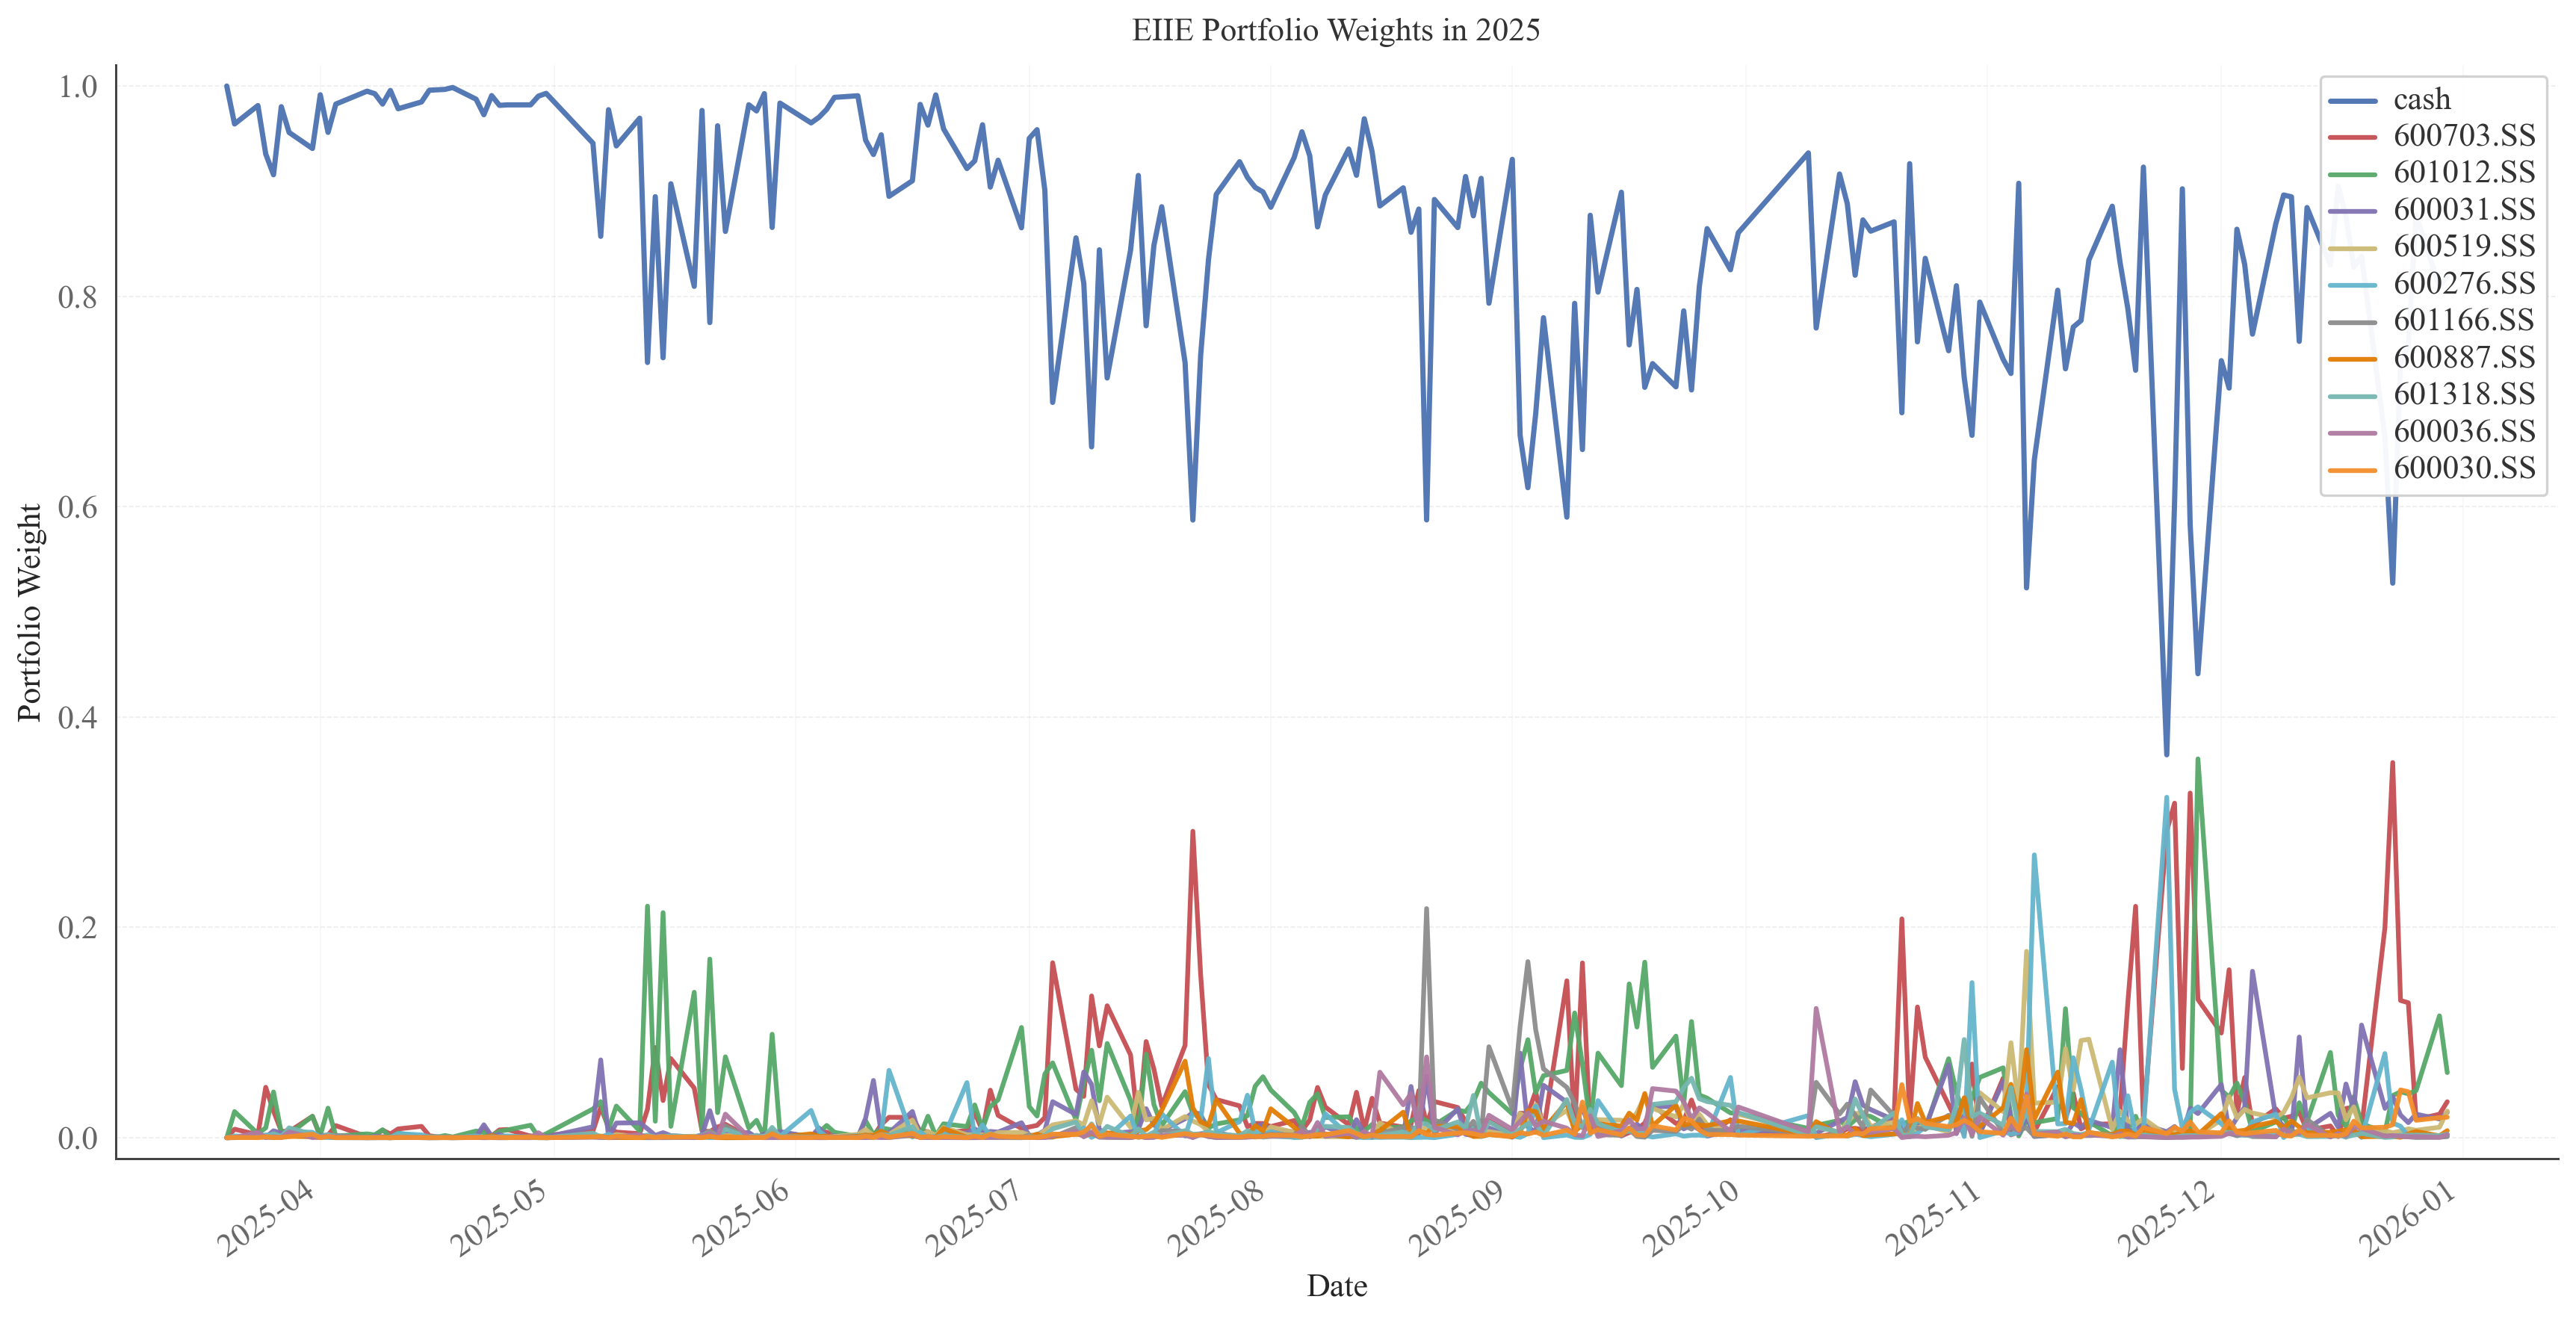

In [62]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

%config InlineBackend.figure_format = "retina"

output_dir = "change_reward_EIIE_sse50_figures"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "axes.unicode_minus": False,

    "figure.dpi": 120,
    "savefig.dpi": 400,

    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9,

    "axes.linewidth": 0.9,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.22,
    "lines.linewidth": 1.8,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# A restrained academic palette for highlighted assets
HIGHLIGHT_COLORS = [
    "#4C72B0", "#C44E52", "#55A868", "#8172B2", "#CCB974",
    "#64B5CD", "#8C8C8C", "#E17C05", "#76B7B2", "#B07AA1",
    "#F28E2B", "#59A14F"
]

def plot_actions_pretty(
    actions,
    raw_df,
    title,
    save_path=None,
    top_k=11,
    figsize=(14.5, 7.5),
    highlight_cash=True,
):
    actions = np.asarray(actions, dtype=np.float32)

    # 1. Build the date axis
    dates = sorted(pd.to_datetime(raw_df["date"]).unique())
    n_steps = actions.shape[0]
    x_dates = pd.to_datetime(dates[-n_steps:]) if len(dates) >= n_steps else np.arange(n_steps)

    # 2. Build labels
    tics = sorted(raw_df["tic"].unique().tolist())
    if actions.shape[1] == len(tics) + 1:
        labels = ["cash"] + tics
    else:
        labels = [f"asset_{i}" for i in range(actions.shape[1])]

    # 3. Select highlighted assets based on average allocation
    avg_weights = actions.mean(axis=0)
    sorted_idx = np.argsort(avg_weights)[::-1]

    if highlight_cash and labels[0] == "cash":
        cash_idx = 0
        stock_idx = [i for i in sorted_idx if i != cash_idx]
        highlight_idx = [cash_idx] + stock_idx[:top_k]
    else:
        cash_idx = None
        highlight_idx = sorted_idx[:top_k]

    fig, ax = plt.subplots(figsize=figsize)

    # 4. Plot non-highlighted assets in the background
    for i in range(actions.shape[1]):
        if i in highlight_idx:
            continue
        ax.plot(
            x_dates,
            actions[:, i],
            color="#B8B8B8",
            linewidth=0.8,
            alpha=0.18,
            zorder=1
        )

    # 5. Plot highlighted assets, including cash in the same style family
    for j, i in enumerate(highlight_idx):
        color = HIGHLIGHT_COLORS[j % len(HIGHLIGHT_COLORS)]
        ax.plot(
            x_dates,
            actions[:, i],
            color=color,
            linewidth=1.9 if labels[i] != "cash" else 2.1,
            alpha=0.95,
            label=labels[i],
            zorder=3
        )

    # 6. Axes styling
    ax.set_title(title, pad=10)
    ax.set_xlabel("Date")
    ax.set_ylabel("Portfolio Weight")
    ax.set_ylim(-0.02, 1.02)

    ax.grid(True, axis="y", linestyle="--", color="#B0B0B0")
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#444444")
    ax.spines["bottom"].set_color("#444444")
    ax.tick_params(axis="both", which="major", length=3.5, width=0.8, color="#444444")

    # 7. Format the x-axis as year-month, e.g. 2023-01
    if isinstance(x_dates[0], (np.datetime64, pd.Timestamp)):
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
        plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

    # 8. Legend in the upper-right corner
    ax.legend(
        loc="upper right",
        ncol=1,
        frameon=True,
        framealpha=0.95,
        facecolor="white",
        edgecolor="#D0D0D0",
        borderpad=0.45,
        labelspacing=0.35,
        handlelength=2.0
    )

    apply_times_new_roman(ax)
    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, bbox_inches="tight")
        if save_path.lower().endswith(".png"):
            fig.savefig(save_path[:-4] + ".pdf", bbox_inches="tight")

    plt.show()


plot_actions_pretty(
    EIIE_results["2023"]["actions"],
    df_portfolio_2023,
    "EIIE Portfolio Weights in 2023",
    top_k=11
)

plot_actions_pretty(
    EIIE_results["2024"]["actions"],
    df_portfolio_2024,
    "EIIE Portfolio Weights in 2024",
    top_k=11
)

plot_actions_pretty(
    EIIE_results["2025"]["actions"],
    df_portfolio_2025,
    "EIIE Portfolio Weights in 2025",
    top_k=11
)
